# Sesión 5 — MUBD

## Clustering no supervisado: de la distancia a la interpretación

**Pregunta de partida:** ¿qué agrupaciones aparecen al comparar las observaciones **sin utilizar etiquetas de clase**?

Empezamos por Iris: elegimos variables y escala, calculamos distancias, construimos un árbol y estudiamos distintos cortes. Después exploramos k-means, k-medoides, CLARA y grupos no convexos.

La especie conocida se reserva para contrastar el resultado **después** de formar los grupos. Un clúster no es automáticamente una especie ni una predicción supervisada.

**Puente con la presentación:**

- Introducción y ausencia de respuesta (diapositivas 3–5) → datos sin `Species`.
- Distancias, enlace, Ward, inercia y árbol (8–18) → jerarquía.
- Hopkins (19) → tendencia a agruparse.
- K-means y variantes (23–34) → ajustes.
- Evaluación interna y externa (35–37) → indicadores y comparación.
- Métodos combinados (38–39) → componentes principales y consolidación.

**Recorrido:** inspeccionar → justificar la escala → elegir distancia y enlace → explorar particiones sin etiquetas → medir compacidad y separación → comparar métodos → interpretar perfiles y limitaciones.

Ni un índice interno ni el porcentaje de variabilidad explicada prueban que exista un «número verdadero» de grupos. Las etiquetas conocidas solo se usan para evaluación externa, nunca para ajustar ni escoger los parámetros en esta demostración.

En VS Code, selecciona el kernel del proyecto y ejecuta las celdas **en orden** con **Shift + Enter**. Abre **Variables** para inspeccionar tablas y **Esquema / Outline** para navegar. Los controles complementan los ejemplos fijos; las funciones pueden llamarse sin widgets. Para comprobar la reproducibilidad, usa **Reiniciar** y **Ejecutar todo**. [Guía de notebooks en VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks).

### Preparación

Vaciamos las variables de la sesión y cargamos las librerías.
Si falta alguna en el kernel seleccionado, descomenta la línea de instalación y ejecútala una vez.
Las funciones de apoyo están incluidas en el propio notebook; puedes desplegar sus celdas para leerlas.

In [1]:
%reset -f

In [2]:
# %pip install numpy pandas matplotlib scipy scikit-learn seaborn ipywidgets threadpoolctl ipykernel

In [3]:
from base64 import b64encode
from io import BytesIO
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Circle, Wedge
from pandas.plotting import scatter_matrix
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, cut_tree
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.spatial import ConvexHull
from scipy.linalg import eigh
from scipy.optimize import linear_sum_assignment
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits

%matplotlib inline
%config InteractiveShell.ast_node_interactivity = "all"
sns.set_theme(style="white", context="notebook", palette="colorblind", rc={
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 100, "lines.linewidth": 2, "lines.markersize": 6,
    "grid.color": "#DCE4E8", "grid.alpha": 0.8,
})
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 30)
SEED = 12345
COLORES_GRUPO = sns.color_palette("colorblind", 10)
MAPA_GRUPOS = ListedColormap(COLORES_GRUPO)
COLOR_BASE, COLOR_ACENTO = COLORES_GRUPO[:2]


def estilo_ejes(ax, cuadricula=False):
    """Cuadrícula discreta solo donde facilita leer magnitudes."""
    ax.set_axisbelow(True)
    if cuadricula:
        ax.grid(axis="y")
    return ax


def imagen_control(fig, descripcion):
    """Muestra Matplotlib en un visor HTML sin acumular salidas al mover un control."""
    archivo = BytesIO()
    fig.savefig(archivo, format="png", dpi=100, bbox_inches="tight")
    plt.close(fig)
    return (f"<img src='data:image/png;base64,{b64encode(archivo.getvalue()).decode()}' "
            f"alt='{descripcion}' style='max-width:100%; height:auto;'>")


def cabecera_widget(titulo):
    """Cabecera granate utilizada en los controles de las sesiones anteriores."""
    return widgets.HTML(
        f"<div style='border-left:4px solid #800000; padding:8px 12px; "
        f"font-size:18px; font-weight:600;'>{titulo}</div>")


def fila_controles(controles):
    """Alinea controles con etiquetas legibles y permite envolverlos en pantallas estrechas."""
    for control in controles:
        if isinstance(control, widgets.Checkbox):
            control.layout.width = "auto"
        else:
            control.style.description_width = "75px"
            control.layout.width = "300px"
    return widgets.HBox(controles, layout=widgets.Layout(
        align_items="center", flex_flow="row wrap", gap="12px"))


def panel_interactivo(titulo, control):
    """Presenta los controles encima de la salida sin alterar sus observadores."""
    *entradas, salida = control.children
    salida.layout.width = "100%"
    return widgets.VBox([
        cabecera_widget(titulo), fila_controles(entradas), salida,
    ], layout=widgets.Layout(width="100%", gap="12px"))

Las funciones de k-means permiten elegir **Lloyd** o **Hartigan–Wong**, con uno o varios inicios.
En Hartigan–Wong se alternan transferencias óptimas y rápidas de observaciones entre grupos.
Las etiquetas de grupo se numeran por orden de aparición y no tienen un significado de clase.

In [4]:
def renumerar(etiquetas):
    equivalencias = {valor: i for i, valor in enumerate(dict.fromkeys(np.asarray(etiquetas).tolist()))}
    return np.array([equivalencias[valor] for valor in etiquetas], dtype=int)


def escalar(tabla):
    return (tabla - tabla.mean()) / tabla.std(ddof=1)


def resumen_particion(datos, etiquetas):
    a = np.asarray(datos, dtype=float)
    grupos = renumerar(etiquetas)
    centros = np.array([a[grupos == i].mean(axis=0) for i in np.unique(grupos)])
    errores = np.sum((a - centros[grupos]) ** 2, axis=1)
    withinss = np.bincount(grupos, weights=errores)
    totss = np.sum((a - a.mean(axis=0)) ** 2)
    return SimpleNamespace(labels_=grupos, cluster_centers_=centros, withinss=withinss,
                           inertia_=withinss.sum(), totss=totss,
                           betweenss=totss - withinss.sum(), size=np.bincount(grupos))


def hartigan_wong(datos, k, n_init=1, random_state=12345, max_iter=100, init=None):
    """Transferencias óptimas y rápidas para minimizar la suma de cuadrados."""
    a = np.asarray(datos, dtype=float)
    rng = np.random.default_rng(random_state)
    unicos = np.unique(a, axis=0)
    if not 1 <= k <= len(unicos):
        raise ValueError("k debe estar entre 1 y el número de observaciones distintas.")
    mejor = None
    for _ in range(n_init if init is None else 1):
        centros = unicos[rng.choice(len(unicos), k, replace=False)].copy() if init is None else np.asarray(init, dtype=float).copy()
        etiquetas = cdist(a, centros, metric="sqeuclidean").argmin(axis=1)
        tamanos = np.bincount(etiquetas, minlength=k).astype(float)
        if (tamanos == 0).any():
            raise ValueError("La inicialización produce un grupo vacío.")
        centros = np.array([a[etiquetas == j].mean(axis=0) for j in range(k)])
        alternativos = etiquetas.copy()

        def transferir(i, destino):
            origen = etiquetas[i]
            centros[origen] = (tamanos[origen] * centros[origen] - a[i]) / (tamanos[origen] - 1)
            centros[destino] = (tamanos[destino] * centros[destino] + a[i]) / (tamanos[destino] + 1)
            tamanos[origen] -= 1
            tamanos[destino] += 1
            etiquetas[i] = destino
            alternativos[i] = origen

        for iteracion in range(max_iter):
            cambios = 0
            # Etapa óptima: examinar todos los destinos posibles.
            for i, punto in enumerate(a):
                origen = etiquetas[i]
                if tamanos[origen] <= 1 or k == 1:
                    continue
                distancias = np.sum((centros - punto) ** 2, axis=1)
                retirada = tamanos[origen] / (tamanos[origen] - 1) * distancias[origen]
                costes = tamanos / (tamanos + 1) * distancias
                costes[origen] = np.inf
                destino = int(costes.argmin())
                alternativos[i] = destino
                if costes[destino] < retirada - 1e-12:
                    transferir(i, destino)
                    cambios += 1
            if cambios == 0:
                break
            # Etapa rápida: probar el último par de grupos candidato.
            for _ in range(max_iter):
                rapidos = 0
                for i, punto in enumerate(a):
                    origen, destino = etiquetas[i], alternativos[i]
                    if origen == destino or tamanos[origen] <= 1:
                        continue
                    retirada = tamanos[origen] / (tamanos[origen] - 1) * np.sum((punto - centros[origen]) ** 2)
                    entrada = tamanos[destino] / (tamanos[destino] + 1) * np.sum((punto - centros[destino]) ** 2)
                    if entrada < retirada - 1e-12:
                        transferir(i, destino)
                        rapidos += 1
                if rapidos == 0:
                    break
        resultado = resumen_particion(a, etiquetas)
        resultado.n_iter_ = iteracion + 1
        if mejor is None or resultado.inertia_ < mejor.inertia_:
            mejor = resultado
    return mejor


def ajustar_kmeans(datos, k, n_init=10, random_state=12345, algoritmo="hartigan-wong", init=None):
    with threadpool_limits(limits=1):
        if algoritmo == "hartigan-wong":
            return hartigan_wong(datos, k, n_init, random_state, init=init)
        if algoritmo != "lloyd":
            raise ValueError("Algoritmo desconocido.")
        inicial = "random" if init is None else np.asarray(init)
        return KMeans(n_clusters=k, n_init=n_init if init is None else 1, init=inicial,
                      algorithm="lloyd", random_state=random_state, max_iter=300).fit(datos)

### Herramientas para representar grupos

La representación por componentes principales proyecta los datos sobre dos ejes.
Las envolventes convexas delimitan las observaciones de cada grupo.

In [5]:
def representar_clusters(datos, etiquetas, titulo="Agrupación", envolventes=True, estandarizar=True, mostrar=True):
    tabla = pd.DataFrame(datos)
    entrada = escalar(tabla) if estandarizar else tabla
    pca = PCA(n_components=2)
    coordenadas = pca.fit_transform(entrada)
    fig, ax = plt.subplots(figsize=(8, 5))
    for grupo in np.unique(etiquetas):
        puntos = coordenadas[np.asarray(etiquetas) == grupo]
        color = COLORES_GRUPO[int(grupo) % 10]
        ax.scatter(puntos[:, 0], puntos[:, 1], s=22, color=color, label=f"Grupo {int(grupo)+1}")
        if envolventes and len(puntos) >= 3 and np.linalg.matrix_rank(puntos - puntos.mean(axis=0)) == 2:
            borde = ConvexHull(puntos).vertices
            ax.fill(puntos[borde, 0], puntos[borde, 1], color=color, alpha=0.15)
    porcentajes = 100 * pca.explained_variance_ratio_
    ax.set(xlabel=f"CP1 ({porcentajes[0]:.1f} %)", ylabel=f"CP2 ({porcentajes[1]:.1f} %)", title=titulo)
    ax.legend(frameon=False)
    fig.tight_layout()
    if not mostrar:
        return imagen_control(fig, titulo)
    plt.show()

def pares_coloreados(tabla, etiquetas):
    colores = [COLORES_GRUPO[int(grupo) % 10] for grupo in etiquetas]
    _ = scatter_matrix(tabla, c=colores, figsize=(9, 9), diagonal="hist", s=15, alpha=0.7)
    plt.show()

## Inspeccionar los datos

Iris contiene 150 flores, cuatro medidas numéricas y una especie. **No incluimos `Species` al calcular distancias ni al ajustar grupos.**

Comprueba las unidades y la dispersión de las cuatro medidas: una variable con mayor variación puede dominar las distancias euclídeas. Los primeros ejemplos trabajan en unidades originales para que podamos ver ese efecto.

El mapa de calor permite contrastar estos datos con las columnas estandarizadas: cada variable pasa a tener media 0 y desviación típica 1, calculadas **sin** la especie. Estandarizar cambia la pregunta que hacemos a los datos; no mejora necesariamente la agrupación.

In [6]:
dataset = load_iris()
iris = pd.DataFrame(dataset.data, columns=["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width"])
iris.index = np.arange(1, len(iris) + 1)
iris["Species"] = pd.Categorical.from_codes(dataset.target, dataset.target_names)
iris

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
146,6.7,3.0,5.2,2.3,virginica
147,6.3,2.5,5.0,1.9,virginica
148,6.5,3.0,5.2,2.0,virginica
149,6.2,3.4,5.4,2.3,virginica


In [7]:
iris2 = iris.iloc[:, :4].copy()
iris2

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width
1,5.1,3.5,1.4,0.2
2,4.9,3.0,1.4,0.2
3,4.7,3.2,1.3,0.2
4,4.6,3.1,1.5,0.2
5,5.0,3.6,1.4,0.2
...,...,...,...,...
146,6.7,3.0,5.2,2.3
147,6.3,2.5,5.0,1.9
148,6.5,3.0,5.2,2.0
149,6.2,3.4,5.4,2.3


#### Gráficos de pares

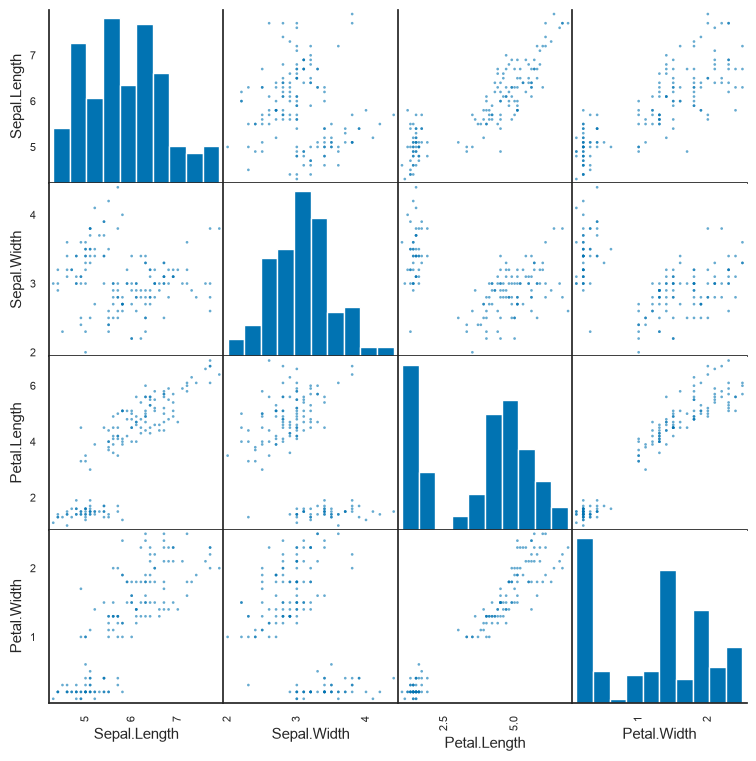

In [8]:
_ = scatter_matrix(iris2, figsize=(9, 9), diagonal="hist", s=15, alpha=0.6)
plt.show()

#### Mapas de calor

Explora los datos originales y los estandarizados por columna, con media cero y desviación típica uno.
Los árboles del mapa reordenan filas y columnas según su proximidad.

In [9]:
iris2_escalado = escalar(iris2)

def mapa_iris(estandarizado):
    tabla = iris2_escalado if estandarizado else iris2
    grafico = sns.clustermap(tabla, method="complete", cmap="vlag", figsize=(9, 7),
                            yticklabels=False, cbar_kws={"label": "Valor estandarizado" if estandarizado else "Valor"})
    titulo = "Iris estandarizado" if estandarizado else "Iris sin escalar"
    _ = grafico.figure.suptitle(titulo, y=1.02)
    display(widgets.HTML(value=imagen_control(grafico.figure, titulo)))

In [10]:
control_mapa = widgets.interactive(
    mapa_iris,
    estandarizado=widgets.Checkbox(value=False, description="Estandarizar columnas"),
)
display(panel_interactivo("Explora los mapas de calor de Iris", control_mapa))

## Clustering jerárquico (diapositivas 8–18)

El algoritmo aglomerativo empieza con una flor por grupo y fusiona dos grupos en cada paso hasta construir un árbol. **No requiere fijar** el número de grupos para construirlo. La alternativa divisiva empieza por un único grupo y lo divide; aquí implementamos solo la aglomerativa.

Distinguimos dos decisiones:

- **Distancia entre observaciones:** euclídea, Manhattan, etc.
- **Enlace entre grupos:** simple (mínimo), completo (máximo), promedio (media de pares) o Ward (mínimo aumento de inercia euclídea).

Calcular las distancias por pares cuesta memoria cuadrática. Además, un dendrograma con miles de hojas es difícil de leer.

### 1. Matriz de distancias

Para las 150 flores de Iris, `pdist` calcula las distancias entre todos los pares **sin duplicarlos**:

$$
\binom{150}{2}=\frac{150\cdot149}{2}=11\,175.
$$

El análisis base usa **distancia euclídea sobre las cuatro medidas originales**. Cambiar la escala o la distancia modifica las proximidades y, por tanto, puede cambiar también el árbol.

In [11]:
d = pdist(iris2, metric="euclidean")
matriz_distancias = pd.DataFrame(squareform(d), index=iris2.index, columns=iris2.index)
matriz_distancias

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,...,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150
1,0.000000,0.538516,0.509902,0.648074,0.141421,0.616441,0.519615,0.173205,0.921954,0.469042,0.374166,0.374166,0.591608,0.994987,0.883176,...,5.788782,4.891830,4.606517,3.896152,4.796874,5.019960,4.636809,4.208325,5.257376,5.136146,4.654031,4.276681,4.459821,4.650806,4.140048
2,0.538516,0.000000,0.300000,0.331662,0.608276,1.090871,0.509902,0.424264,0.509902,0.173205,0.866025,0.458258,0.141421,0.678233,1.360147,...,5.860034,4.959839,4.650806,3.915354,4.860041,5.072475,4.702127,4.180909,5.320714,5.206726,4.700000,4.249706,4.498889,4.718050,4.153312
3,0.509902,0.300000,0.000000,0.244949,0.509902,1.086278,0.264575,0.412311,0.435890,0.316228,0.883176,0.374166,0.264575,0.500000,1.363818,...,6.040695,5.092151,4.806246,4.066940,5.026927,5.228767,4.868265,4.334743,5.475400,5.353504,4.864155,4.430576,4.661545,4.848711,4.298837
4,0.648074,0.331662,0.244949,0.000000,0.648074,1.166190,0.331662,0.500000,0.300000,0.316228,1.000000,0.374166,0.264575,0.519615,1.529706,...,5.932116,4.962862,4.669047,3.926831,4.910193,5.104900,4.760252,4.177320,5.349766,5.232590,4.745524,4.288356,4.533211,4.719110,4.149699
5,0.141421,0.608276,0.509902,0.648074,0.000000,0.616441,0.458258,0.223607,0.921954,0.529150,0.424264,0.346410,0.640312,0.974679,0.916515,...,5.843800,4.920366,4.645428,3.934463,4.844585,5.061620,4.686150,4.246175,5.297169,5.173007,4.701064,4.330127,4.504442,4.678675,4.173727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,4.654031,4.700000,4.864155,4.745524,4.701064,4.284857,4.796874,4.598913,4.914265,4.666905,4.503332,4.597826,4.784349,5.235456,4.713809,...,1.345362,0.700000,0.663325,0.948683,0.360555,0.424264,0.244949,1.034408,0.734847,0.616441,0.000000,0.781025,0.360555,0.670820,0.948683
147,4.276681,4.249706,4.430576,4.288356,4.330127,3.988734,4.384062,4.200000,4.429447,4.220190,4.170132,4.184495,4.324350,4.764452,4.453089,...,1.892089,1.191638,0.793725,0.624500,0.959166,1.063015,0.943398,0.547723,1.307670,1.284523,0.781025,0.000000,0.583095,1.067708,0.655744
148,4.459821,4.498889,4.661545,4.533211,4.504442,4.102438,4.593474,4.397727,4.701064,4.457578,4.316248,4.387482,4.576024,5.025933,4.553021,...,1.529706,0.721110,0.387298,0.670820,0.469042,0.608276,0.519615,0.774597,0.842615,0.793725,0.360555,0.583095,0.000000,0.616441,0.640312
149,4.650806,4.718050,4.848711,4.719110,4.678675,4.264974,4.749737,4.589118,4.888763,4.672259,4.511097,4.561798,4.791659,5.205766,4.750789,...,1.702939,0.244949,0.624500,0.900000,0.787401,0.624500,0.818535,0.948683,0.806226,0.624500,0.670820,1.067708,0.616441,0.000000,0.768115


### 2. Jerarquización: enlace completo

In [12]:
hc = linkage(d, method="complete")

### 3. Dendrograma

Cada fusión une dos ramas a una **altura de disimilitud**. En este ejemplo, con enlace completo, esa altura representa la mayor distancia entre observaciones de los dos grupos fusionados; **no** indica cuántas flores contiene cada rama.

Con Ward, la altura de una fusión no se interpreta simplemente como la distancia original entre dos flores: el criterio busca minimizar el incremento de inercia intra.

El orden horizontal de las hojas puede cambiar sin alterar la estructura del árbol.

**Para pensar:** ¿por qué un corte que parece claro en el dibujo no garantiza una partición estable frente a cambios de escala o distancia?

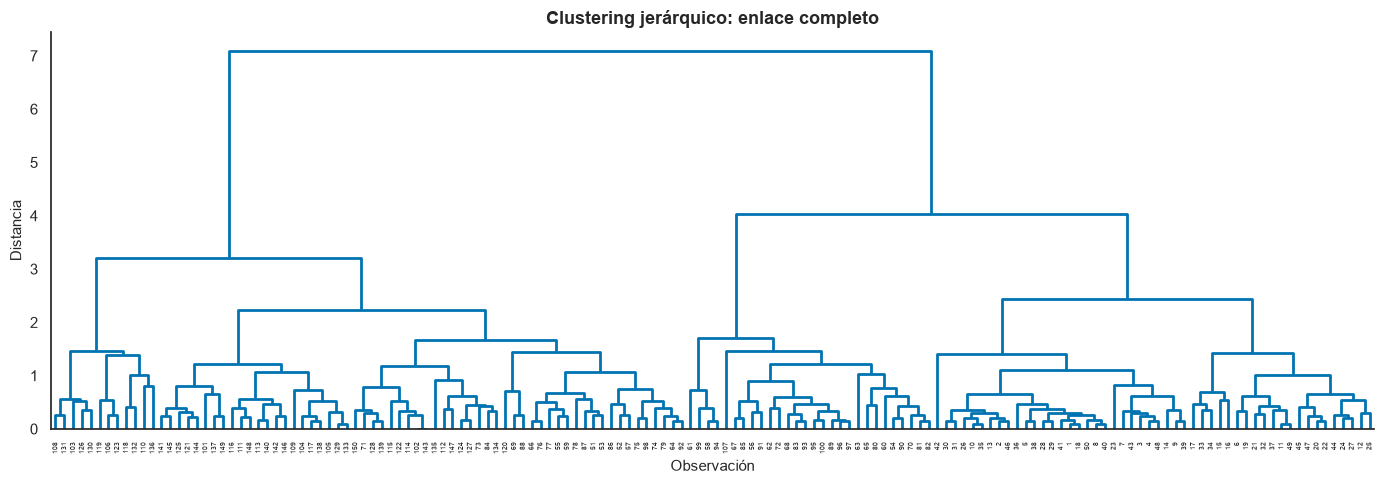

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
_ = dendrogram(hc, labels=iris2.index.to_list(), leaf_rotation=90, leaf_font_size=5,
               color_threshold=0, above_threshold_color=COLOR_BASE, ax=ax)
_ = ax.set(xlabel="Observación", ylabel="Distancia", title="Clustering jerárquico: enlace completo")
fig.tight_layout()
plt.show()

#### Explorar las decisiones: escala, distancia y enlace

Cambia **una decisión a la vez** en el control y observa cómo responde el dendrograma. ¿Se alteran las primeras fusiones? ¿Y las alturas de las ramas?

La correlación cofenética se calcula con las distancias usadas para construir **ese mismo árbol**. Un valor alto indica que el árbol reproduce bien esas disimilitudes, pero no demuestra que exista una partición «verdadera»; tampoco conviene comparar sus valores entre distancias de escalas distintas sin atender a ese cambio.

**Restricción:** Ward solo admite aquí distancia euclídea si queremos interpretar el criterio como incremento de inercia. El control impide combinarlo con Manhattan.

Este experimento no modifica `hc`, el árbol fijo utilizado en las siguientes celdas. Si el control no aparece, ejecuta la función directamente en una nueva celda:

```python
display(widgets.HTML(value=explorar_arbol("euclidean", "complete", False)))
```

In [14]:
def explorar_arbol(distancia="euclidean", enlace="complete", estandarizar=False):
    """Explora un árbol nuevo sin modificar hc, ct ni los resultados fijos."""
    if enlace == "ward" and distancia != "euclidean":
        raise ValueError("Para interpretar Ward como incremento de inercia usa distancia euclídea.")
    tabla = escalar(iris2) if estandarizar else iris2
    disimilitudes = pdist(tabla, metric=distancia)
    arbol = linkage(disimilitudes, method=enlace)
    calidad = cophenet(arbol, disimilitudes)[0]
    fig, ax = plt.subplots(figsize=(12, 4))
    _ = dendrogram(arbol, no_labels=True, ax=ax, color_threshold=0,
                   above_threshold_color=COLOR_BASE)
    _ = ax.set(title=f"{enlace.title()} · {distancia} · "
                     f"{'estandarizado' if estandarizar else 'sin escalar'}",
               xlabel="Flores ordenadas por el árbol", ylabel="Altura de la fusión")
    fig.tight_layout()
    return imagen_control(fig, "Dendrograma comparativo de Iris") + (
        f"<p>Correlación cofenética con su propia distancia: <b>{calidad:.3f}</b>. "
        "Un valor alto no demuestra que exista un número verdadero de grupos.</p>")

selector_distancia = widgets.Dropdown(options=[("Euclídea", "euclidean"),
                                               ("Manhattan", "cityblock")],
                                     value="euclidean", description="Distancia")
selector_enlace = widgets.Dropdown(options=[("Completo", "complete"),
                                            ("Promedio", "average"),
                                            ("Simple", "single"), ("Ward", "ward")],
                                  value="complete", description="Enlace")
selector_escala = widgets.Checkbox(value=False, description="Estandarizar")
visor_arbol = widgets.HTML(layout=widgets.Layout(width="100%"))

def actualizar_arbol(cambio=None):
    if cambio is not None and cambio["name"] != "value":
        return
    if selector_distancia.value != "euclidean" and selector_enlace.value == "ward":
        selector_enlace.value = "complete"
        return  # El cambio de enlace llama al observador otra vez.
    visor_arbol.value = explorar_arbol(selector_distancia.value, selector_enlace.value,
                                      selector_escala.value)

for control in (selector_distancia, selector_enlace, selector_escala):
    control.observe(actualizar_arbol, names="value")
actualizar_arbol()
control_arbol = widgets.VBox([
    cabecera_widget("Explora distancias y enlaces"),
    fila_controles([selector_distancia, selector_enlace, selector_escala]),
    visor_arbol,
], layout=widgets.Layout(width="100%", gap="12px"))
display(control_arbol)

### 4. Calidad del árbol (diapositiva 17)

La **distancia cofenética** entre dos flores es la altura a la que sus ramas se unen por primera vez. Para cada par, comparamos esa altura con la distancia original entre las dos observaciones.

La **correlación cofenética** resume hasta qué punto el dendrograma conserva el orden de proximidades de los datos. Una correlación alta **no** prueba que haya grupos naturales ni que el corte en tres grupos sea bueno.

La diapositiva menciona 0,75 como orientación, no como umbral universal. Compara siempre el árbol con las distancias calculadas sobre **las mismas variables y escala** con que se construyó.

In [15]:
cop_dist = cophenet(hc)
np.corrcoef(d, cop_dist)[0, 1]

np.float64(0.7269856836284623)

### 5. Elegir una partición (diapositivas 12–13 y 18)

Al cortar el árbol en $k$ grupos, la **inercia intra** suma las distancias cuadráticas de cada observación al centro de su grupo:

$$
W_k=\sum_{g=1}^{k}\sum_{i\in g}\lVert x_i-\bar{x}_g\rVert^2.
$$

La inercia total se descompone en **intra + entre**. La proporción de variabilidad explicada es:

$$
\frac{B_k}{T}=1-\frac{W_k}{T}.
$$

Esta proporción aumenta al añadir grupos, incluso si los nuevos grupos no aportan una interpretación útil. No la maximices sin considerar simplicidad, estabilidad y contexto. Aquí calculamos inercia mediante distancias euclídeas a centroides **aunque el árbol se haya construido con enlace completo**.

#### Regla del codo: inercia dentro de los grupos

Busca una caída pronunciada de la inercia seguida de reducciones menores. El codo no siempre es nítido ni coincide con otros indicadores: compara también el tamaño, la interpretación y la estabilidad de los grupos.

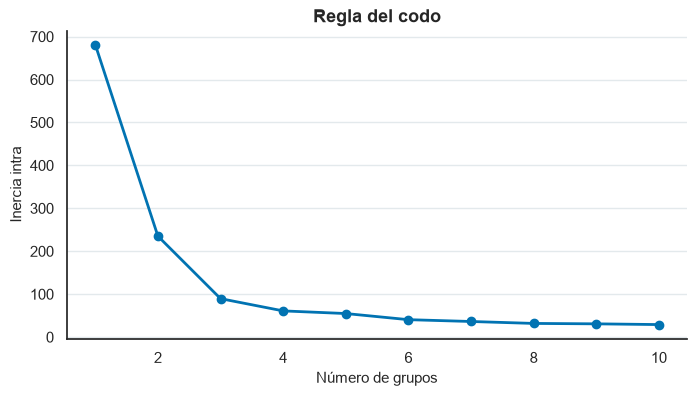

In [16]:
inercia_hc = pd.Series({k: resumen_particion(iris2, cut_tree(hc, n_clusters=k).ravel()).inertia_
                        for k in range(1, 11)}, name="Inercia intra")
ax = inercia_hc.plot(marker="o", color=COLOR_BASE)
_ = ax.set(xlabel="Número de grupos", ylabel="Inercia intra", title="Regla del codo")
_ = estilo_ejes(ax, cuadricula=True)
plt.show()

#### Número de grupos según 26 indicadores

Calculamos KL, CH, Hartigan, CCC, Scott, Marriott, TraceCovW, TraceW, Friedman, Rubin, C-index, Davies–Bouldin, silhouette, Duda, pseudo-t², Beale, Ratkowsky, Ball, punto-biserial, Frey, McClain, Dunn, Hubert, SD, D-index y SDbw.

Cada criterio aplica su regla de elección. **Hubert y D-index son diagnósticos gráficos y no votan.** Las pruebas de división examinan una división local en dos del grupo de mayor inercia; los criterios sin recomendación válida aparecen como ausentes y tampoco votan.

El **coeficiente silhouette** de una observación compara su distancia media a las demás flores de su grupo, $a(i)$, con la menor distancia media a otro grupo, $b(i)$:

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}.
$$

Un valor cercano a **1** indica buena separación; uno cercano a **0**, una posición fronteriza; y uno **negativo**, mayor proximidad a otro grupo. La media resume la partición.

El índice de **Dunn** favorece separación mínima alta frente a diámetro máximo interno. **Ninguna votación equivale a una prueba de hipótesis:** el valor más votado no es automáticamente el número correcto de grupos. Revisa el desacuerdo entre índices y los supuestos de cada uno.

In [17]:
def indice_dunn(distancias, etiquetas):
    D = np.asarray(distancias)
    grupos = np.unique(etiquetas)
    diametro = max(D[np.ix_(etiquetas == g, etiquetas == g)].max() for g in grupos)
    separacion = min(D[np.ix_(etiquetas == g, etiquetas == h)].min()
                     for i, g in enumerate(grupos) for h in grupos[i+1:])
    return separacion / diametro if diametro > 0 else np.inf


def evaluar_indices(datos, metodo="ward", min_k=2, max_k=15, random_state=12345):
    """26 criterios: 24 reglas de elección y dos diagnósticos gráficos."""
    a = np.asarray(datos, dtype=float)
    n, p = a.shape
    D = squareform(pdist(a))
    superiores = np.triu_indices(n, 1)
    distancias = D[superiores]
    ordenadas = np.sort(distancias)
    particiones = {1: np.zeros(n, dtype=int)}
    arbol = None if metodo == "kmeans" else linkage(pdist(a), method=metodo)
    for k in range(2, max_k + 2):
        particiones[k] = (ajustar_kmeans(a, k, n_init=1, random_state=random_state).labels_
                          if metodo == "kmeans" else renumerar(cut_tree(arbol, n_clusters=k).ravel()))
    total_centrado = np.sum((a - a.mean(axis=0)) ** 2)
    T = a.T @ a
    s = np.sqrt(np.maximum(np.linalg.eigvalsh(T / (n - 1))[::-1], 1e-15))
    determinante_T = np.linalg.slogdet(T)[1]
    cache = {}
    for k, etiquetas in particiones.items():
        r = resumen_particion(a, etiquetas)
        etiquetas = r.labels_
        residuos = a - r.cluster_centers_[etiquetas]
        W = residuos.T @ residuos
        B = T - W
        mismas = etiquetas[superiores[0]] == etiquetas[superiores[1]]
        dentro, fuera = distancias[mismas], distancias[~mismas]
        var_grupos = np.array([a[etiquetas == j].var(axis=0) for j in range(k)])
        norma_var = np.linalg.norm(var_grupos, axis=1)
        scatt = norma_var.mean() / np.linalg.norm(a.var(axis=0))
        radio = np.sqrt(norma_var.sum()) / k
        centros_D = squareform(pdist(r.cluster_centers_))
        dis = ((pdist(r.cluster_centers_).max() / pdist(r.cluster_centers_).min())
               * np.sum(1 / centros_D.sum(axis=1))) if k > 1 else np.nan
        cache[k] = dict(r=r, labels=etiquetas, W=W, B=B, dentro=dentro, fuera=fuera,
                        scatt=scatt, radio=radio, dis=dis, centros_D=centros_D)

    filas, criticos = [], []
    for k in range(min_k, max_k + 1):
        c = cache[k]
        r, etiquetas, W, B = c["r"], c["labels"], c["W"], c["B"]
        previo, siguiente = cache[k-1]["r"], cache[k+1]["r"]
        dentro, fuera = c["dentro"], c["fuera"]
        intra = r.inertia_
        signo, logdetW = np.linalg.slogdet(W)
        dispersion = np.sqrt(r.withinss / r.size)
        ratios = (dispersion[:, None] + dispersion[None, :]) / np.where(c["centros_D"] > 0, c["centros_D"], np.inf)
        m = len(dentro)
        minimo, maximo = ordenadas[:m].sum(), ordenadas[-m:].sum()
        u = s / (np.prod(s) / k) ** (1 / p)
        p1 = min(int((u >= 1).sum()), k - 1)
        if 0 < p1 < p:
            u = s / (np.prod(s[:p1]) / k) ** (1 / p1)
            suma = np.sum(1 / (n + u[:p1])) + np.sum(u[p1:] ** 2 / (n + u[p1:]))
            dimension = p1
        else:
            suma, dimension = np.sum(1 / (n + u)), p
        esperado_R2 = 1 - suma / np.sum(u ** 2) * (n - k) ** 2 / n * (1 + 4 / n)
        R2 = 1 - np.trace(W) / np.trace(T)
        ccc = (np.log((1 - esperado_R2) / (1 - R2)) * np.sqrt(n * dimension / 2)
               / (0.001 + esperado_R2) ** 1.2)

        # Pruebas de división: examinar una división local del grupo más disperso.
        padre = int(r.withinss.argmax())
        local = a[etiquetas == padre]
        division = ajustar_kmeans(local, 2, n_init=1, random_state=random_state)
        wl = division.inertia_
        wm = r.withinss[padre]
        nm = len(local)
        duda = wl / wm
        critica_duda = 1 - 2 / (np.pi * p) - 3.2 * np.sqrt(2 * (1 - 8 / np.pi ** 2) / (nm * p))
        pseudo = (wm - wl) / (wl / (nm - 2))
        beale = ((wm - wl) / wl) / ((nm - 1) / (nm - 2) * (2 ** (2 / p) - 1))
        criticos.append({"k": k, "Duda": critica_duda,
                         "PseudoT2": (1 - critica_duda) / critica_duda * (nm - 2),
                         "Beale": stats.f.sf(beale, p, (nm - 2) * p)})

        dist_centro = np.linalg.norm(a - r.cluster_centers_[etiquetas], axis=1)
        densidades = np.bincount(etiquetas, weights=(dist_centro <= c["radio"]), minlength=k)
        dens_bw = 0.0
        for i in range(k):
            for j in range(i+1, k):
                candidatos = a[(etiquetas == i) | (etiquetas == j)]
                centro = (r.cluster_centers_[i] + r.cluster_centers_[j]) / 2
                cantidad = (np.linalg.norm(candidatos - centro, axis=1) <= c["radio"]).sum()
                denominador = max(densidades[i], densidades[j])
                dens_bw += cantidad / denominador if denominador else 0
        Q = cdist(r.cluster_centers_[etiquetas], r.cluster_centers_[etiquetas])
        varP = np.linalg.norm(D.var(axis=0))
        varQ = np.linalg.norm(Q.var(axis=0))
        hubert = np.sum((D - D.mean())[superiores] * (Q - Q.mean())[superiores]) / (len(distancias) * varP * varQ)
        proxima = cache[k+1]
        denominador_frey = proxima["dentro"].mean() - dentro.mean()
        kl_num = (k-1) ** (2/p) * previo.inertia_ - k ** (2/p) * intra
        kl_den = k ** (2/p) * intra - (k+1) ** (2/p) * siguiente.inertia_
        filas.append({
            "k": k, "KL": abs(kl_num / kl_den),
            "CH": ((total_centrado - intra) / (k-1)) / (intra / (n-k)),
            "Hartigan": (intra / siguiente.inertia_ - 1) * (n-k), "CCC": ccc,
            "Scott": n * (determinante_T - logdetW), "Marriott": k ** 2 * np.linalg.det(W),
            "TraceCovW": np.var(W, axis=0, ddof=1).sum(), "TraceW": np.trace(W),
            "Friedman": np.trace(np.linalg.inv(W) * B), "Rubin": np.trace(T) / np.trace(W),
            "Cindex": (dentro.sum() - minimo) / (maximo - minimo), "DB": ratios.max(axis=1).mean(),
            "Silhouette": silhouette_score(D, etiquetas, metric="precomputed"),
            "Duda": duda, "PseudoT2": pseudo, "Beale": beale,
            "Ratkowsky": np.sqrt(1 - np.sum((a - r.cluster_centers_[etiquetas]) ** 2, axis=0)
                                    / np.sum((a - a.mean(axis=0)) ** 2, axis=0)).mean() / np.sqrt(k),
            "Ball": intra / k,
            "PointBiserial": (fuera.mean() - dentro.mean()) * np.sqrt(len(fuera)*len(dentro))
                              / len(distancias) / distancias.std(ddof=1),
            "Frey": (proxima["fuera"].mean() - fuera.mean()) / denominador_frey,
            "McClain": (dentro.mean()/len(dentro)) / (fuera.mean()/len(fuera)),
            "Dunn": indice_dunn(D, etiquetas), "Hubert": hubert,
            "SDindex": cache[max_k]["dis"] * c["scatt"] + c["dis"],
            "Dindex": dist_centro.mean(), "SDbw": c["scatt"] + 2 * dens_bw / (k * (k-1)),
        })
    indices = pd.DataFrame(filas).set_index("k")
    criticos = pd.DataFrame(criticos).set_index("k")
    recomendaciones = {}
    maximos = ["KL", "CH", "CCC", "Silhouette", "Ratkowsky", "PointBiserial", "Dunn"]
    minimos = ["Cindex", "DB", "McClain", "SDindex", "SDbw"]
    for nombre in maximos:
        recomendaciones[nombre] = indices[nombre].idxmax()
    for nombre in minimos:
        recomendaciones[nombre] = indices[nombre].idxmin()
    for nombre in ["Hartigan", "Scott", "TraceCovW", "Friedman", "Ball"]:
        recomendaciones[nombre] = (indices[nombre] - indices[nombre].shift(-1)).abs().idxmax()
    for nombre, maximizar in [("Marriott", True), ("TraceW", True), ("Rubin", False)]:
        diferencias = indices[nombre].shift(1) - 2 * indices[nombre] + indices[nombre].shift(-1)
        recomendaciones[nombre] = diferencias.idxmax() if maximizar else diferencias.idxmin()
    condiciones = {"Duda": indices["Duda"] >= criticos["Duda"],
                   "PseudoT2": indices["PseudoT2"] <= criticos["PseudoT2"],
                   "Beale": criticos["Beale"] >= 0.1, "Frey": indices["Frey"] < 1}
    for nombre, condicion in condiciones.items():
        candidatos = indices.index[condicion]
        recomendaciones[nombre] = (max(min_k, int(candidatos[0]) - 1) if nombre == "Frey" else candidatos[0]) if len(candidatos) else np.nan
    best = pd.Series(recomendaciones, name="k recomendado").astype("Int64")
    votos = best.dropna().value_counts().sort_index()
    ganador = int(votos.idxmax())
    return SimpleNamespace(All_index=indices, Best_n=best.to_frame(), Votes=votos,
                           Best_partition=particiones[ganador], Critical=criticos, partitions=particiones)

In [18]:
NB = evaluar_indices(iris2, metodo="ward", min_k=2, max_k=15, random_state=SEED)
NB.Best_n

,k recomendado
KL,2
CH,3
CCC,3
Silhouette,2
Ratkowsky,2
PointBiserial,2
Dunn,2
Cindex,15
DB,2
McClain,2


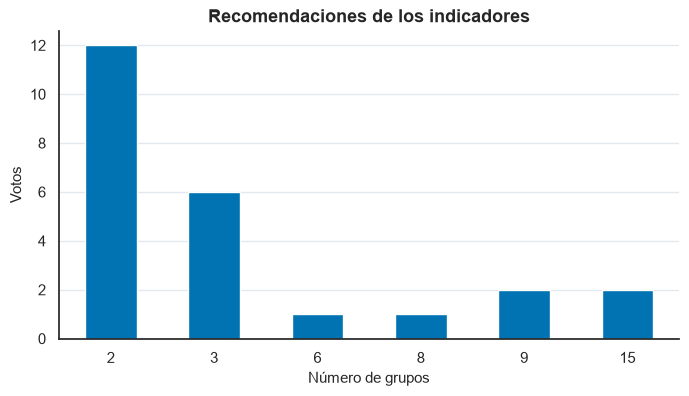

In [19]:
ax = NB.Votes.plot.bar(rot=0, color=COLOR_BASE)
_ = ax.set(xlabel="Número de grupos", ylabel="Votos", title="Recomendaciones de los indicadores")
_ = estilo_ejes(ax, cuadricula=True)
plt.show()

#### Cortar el árbol en tres grupos

El control permite explorar otras particiones. Los rectángulos señalan las ramas que forman cada grupo.

In [20]:
ct = pd.Series(renumerar(cut_tree(hc, n_clusters=3).ravel()), index=iris.index, name="grupo")

def particion_jerarquica(k):
    grupos = renumerar(cut_tree(hc, n_clusters=k).ravel())
    fig, ax = plt.subplots(figsize=(14, 5))
    dibujado = dendrogram(hc, no_labels=True, link_color_func=lambda nodo: "#5B6770", ax=ax)
    orden = np.asarray(dibujado["leaves"])
    altura = (hc[-k, 2] + hc[-k+1, 2]) / 2
    for grupo in np.unique(grupos):
        posiciones = np.flatnonzero(grupos[orden] == grupo)
        color = COLORES_GRUPO[int(grupo) % 10]
        ax.add_patch(Rectangle((10 * posiciones.min(), 0), 10 * len(posiciones), altura,
                               fill=False, edgecolor=color, linewidth=2))
    ax.set(xlabel="Observaciones ordenadas por el árbol", ylabel="Distancia", title=f"Partición en {k} grupos")
    fig.tight_layout()
    display(widgets.HTML(value=imagen_control(fig, f"Dendrograma dividido en {k} grupos")))
    resumen = resumen_particion(iris2, grupos)
    print(f"Variabilidad explicada: {resumen.betweenss / resumen.totss:.1%}")
    return pd.Series(np.bincount(grupos), index=np.arange(1, k+1), name="Tamaño del grupo")

In [21]:
control_jerarquia = widgets.interactive(
    particion_jerarquica,
    k=widgets.IntSlider(value=3, min=2, max=8, description="Grupos", continuous_update=False),
)
display(panel_interactivo("Explora el corte del árbol", control_jerarquia))

### Clustering sobre componentes principales y consolidación (diapositivas 38–39)

Primero estandarizamos las cuatro medidas de Iris y calculamos **todas** las componentes principales. A continuación construimos un árbol en ese espacio y, si activamos la opción, consolidamos la partición con k-means iniciado en sus centroides.

**¿Reduce PCA la dimensión aquí? No.** Conservamos todas las componentes: la rotación mantiene las distancias euclídeas entre flores estandarizadas. Si retuviésemos solo algunas, sí cambiarían las distancias; podríamos eliminar ruido, pero también señal.

El gráfico muestra los grupos sobre **dos ejes proyectados**, aunque el ajuste utiliza **todas las componentes**. Al mover estos controles no cambia `ct`, la partición jerárquica fija que se usa después.

In [22]:
def hcpc(k, consolidar):
    coordenadas = PCA().fit_transform(iris2_escalado)
    arbol = linkage(pdist(coordenadas), method="complete")
    inicial = renumerar(cut_tree(arbol, n_clusters=k).ravel())
    centros = np.array([coordenadas[inicial == j].mean(axis=0) for j in range(k)])
    grupos = ajustar_kmeans(coordenadas, k, init=centros).labels_ if consolidar else inicial
    grafico = representar_clusters(iris2_escalado, grupos, titulo="Clustering sobre componentes principales",
                                   estandarizar=False, mostrar=False)
    display(widgets.HTML(value=grafico))
    return SimpleNamespace(labels_=grupos, tree_=arbol, scores_=coordenadas)

def explorar_hcpc(k, consolidar):
    global HC
    HC = hcpc(k, consolidar)

In [23]:
control_hcpc = widgets.interactive(
    explorar_hcpc,
    k=widgets.IntSlider(value=3, min=2, max=8, description="Grupos", continuous_update=False),
    consolidar=widgets.Checkbox(value=True, description="Consolidar con k-means"),
)
display(panel_interactivo("Explora el árbol sobre componentes principales", control_hcpc))

### 6. Representación de los tres grupos jerárquicos

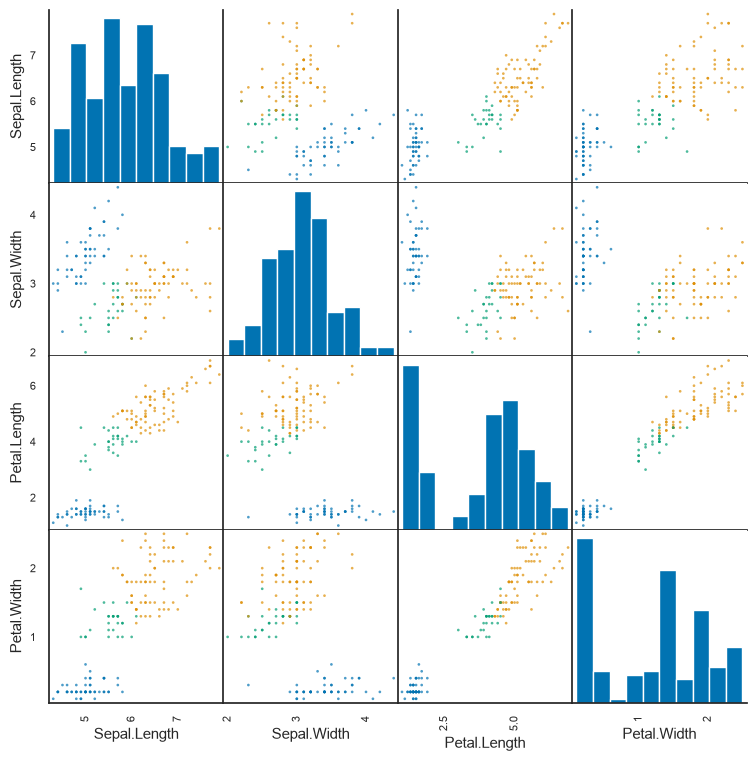

In [24]:
pares_coloreados(iris2, ct.to_numpy())

#### Dos primeras componentes principales de las variables originales

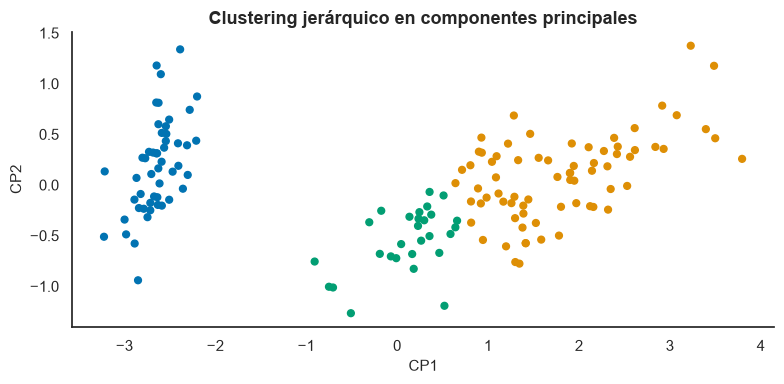

In [25]:
pr = PCA().fit(iris2)
scores = pr.transform(iris2)
x, y = scores[:, 0], scores[:, 1]
fig, ax = plt.subplots()
_ = ax.scatter(x, y, c=ct, cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=24)
_ = ax.set(xlabel="CP1", ylabel="CP2", title="Clustering jerárquico en componentes principales")
fig.tight_layout()
plt.show()

#### Envolventes convexas sobre las dos primeras componentes de las variables estandarizadas

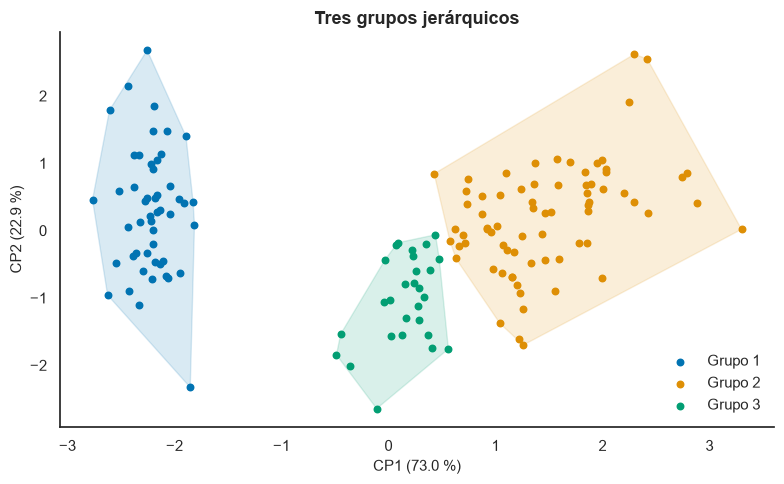

In [26]:
representar_clusters(iris2, ct.to_numpy(), titulo="Tres grupos jerárquicos")

### 7. Correspondencia con las especies conocidas (diapositivas 5 y 22)

**Evaluación externa:** las especies no intervinieron en la distancia, el enlace ni el corte. Después de la partición se asigna cada grupo a una especie para **describir** el grado de coincidencia. Los números de grupo son arbitrarios: no compares directamente «grupo 1» con «especie 1». Una coincidencia alta no vuelve supervisado el ajuste ni autoriza a elegir retrospectivamente el corte que maximiza acierto con las especies. El índice de Rand ajustado que se usa más adelante compara parejas de observaciones y no necesita renombrar etiquetas; su valor cercano a 0 indica similitud aproximadamente aleatoria, y 1 indica particiones idénticas.

In [27]:
tabla_especies = pd.crosstab(iris["Species"], ct + 1)
tabla_especies

grupo,1,2,3
Species,,,
setosa,50,0,0
versicolor,0,23,27
virginica,0,49,1


In [28]:
filas, columnas = linear_sum_assignment(-tabla_especies.to_numpy())
correspondencia = {int(columna): int(fila) for fila, columna in zip(filas, columnas)}
cl = ct.map(correspondencia)
t_pred = pd.crosstab(iris["Species"], cl + 1)
t_pred
np.trace(t_pred.to_numpy()) / t_pred.to_numpy().sum()

grupo,1,2,3
Species,,,
setosa,50,0,0
versicolor,0,27,23
virginica,0,1,49


np.float64(0.84)

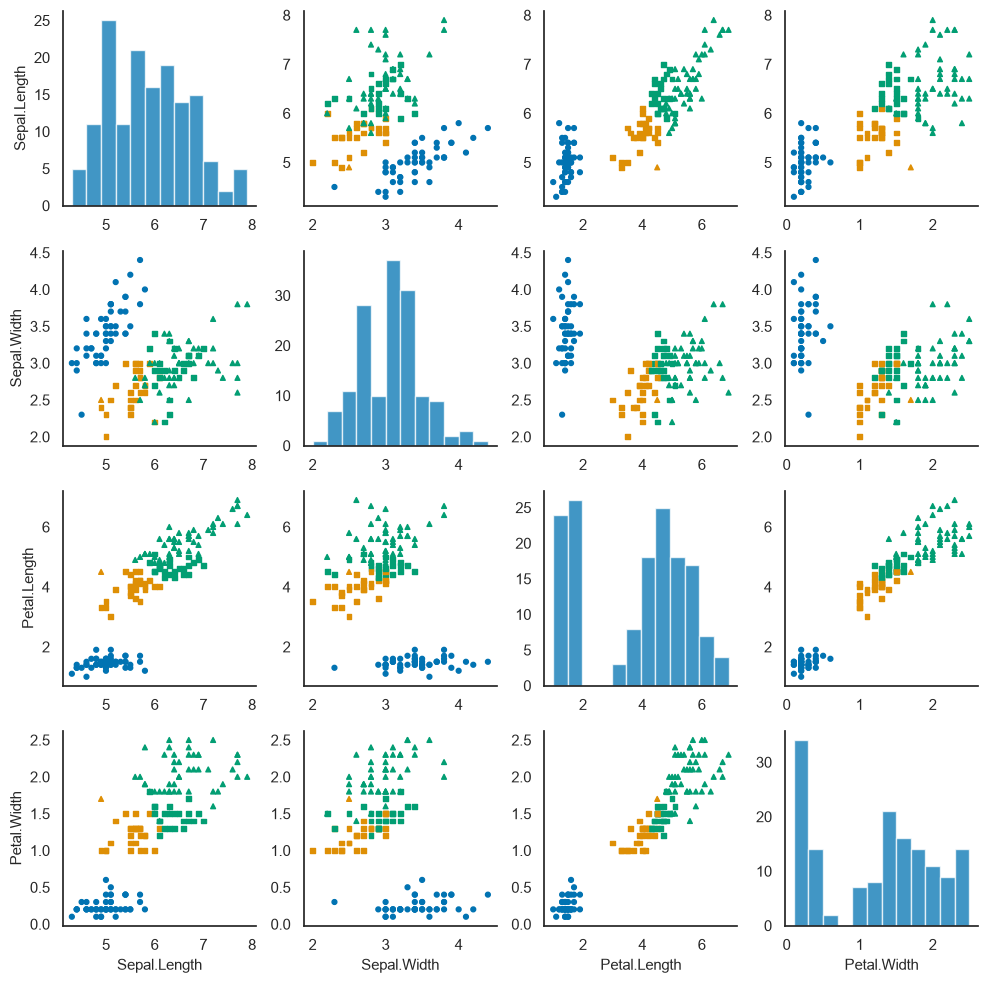

In [29]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
marcadores = ["o", "s", "^"]
for i, nombre_y in enumerate(iris2.columns):
    for j, nombre_x in enumerate(iris2.columns):
        ax = axes[i, j]
        if i == j:
            _ = ax.hist(iris2[nombre_x], bins=12, color=COLOR_BASE, alpha=0.75)
        else:
            for especie, marcador in enumerate(marcadores):
                mascara = dataset.target == especie
                _ = ax.scatter(iris2.loc[mascara, nombre_x], iris2.loc[mascara, nombre_y],
                               c=cl.loc[mascara], cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5,
                               marker=marcador, s=12)
        if i == 3: _ = ax.set_xlabel(nombre_x)
        if j == 0: _ = ax.set_ylabel(nombre_y)
fig.tight_layout()
plt.show()

### 8. Relación entre dos dendrogramas

Construimos árboles con enlace completo y promedio. Las líneas unen la misma observación en ambos árboles.

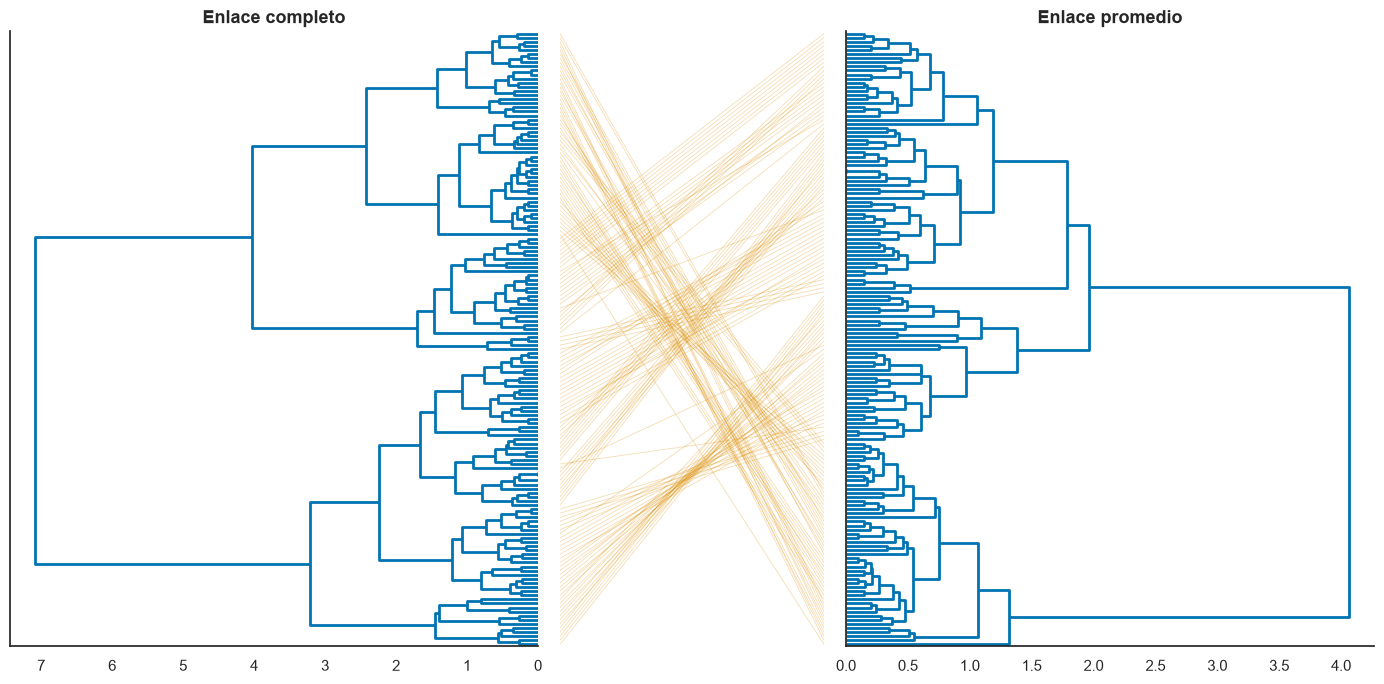

In [30]:
hc1 = linkage(d, method="complete")
hc2 = linkage(d, method="average")

def tanglegram(izquierdo, derecho):
    fig, axes = plt.subplots(1, 3, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1, 2]})
    a = dendrogram(izquierdo, orientation="left", no_labels=True, ax=axes[0],
                   color_threshold=0, above_threshold_color=COLOR_BASE)
    b = dendrogram(derecho, orientation="right", no_labels=True, ax=axes[2],
                   color_threshold=0, above_threshold_color=COLOR_BASE)
    posiciones_a = {observacion: 5 + 10 * i for i, observacion in enumerate(a["leaves"])}
    posiciones_b = {observacion: 5 + 10 * i for i, observacion in enumerate(b["leaves"])}
    for observacion in posiciones_a:
        axes[1].plot([0, 1], [posiciones_a[observacion], posiciones_b[observacion]],
                     color=COLOR_ACENTO, alpha=0.3, linewidth=0.6)
    for ax in axes:
        ax.set_ylim(0, 10 * len(a["leaves"]))
    axes[1].set(xlim=(0, 1))
    axes[1].axis("off")
    axes[0].set_title("Enlace completo")
    axes[2].set_title("Enlace promedio")
    fig.tight_layout()
    plt.show()

tanglegram(hc1, hc2)

In [31]:
dend_list = {"Completo": hc1, "Promedio": hc2}
pd.DataFrame({nombre: cophenet(arbol) for nombre, arbol in dend_list.items()}).corr()

,Completo,Promedio
Completo,1.000000,0.619512
Promedio,0.619512,1.000000


#### Cuatro dendrogramas: completo, promedio, Ward y simple

In [32]:
hc3 = linkage(d, method="ward")
hc4 = linkage(d, method="single")
dend_list.update({"Ward": hc3, "Simple": hc4})
cor_dend = pd.DataFrame({nombre: cophenet(arbol) for nombre, arbol in dend_list.items()}).corr()
cor_dend

,Completo,Promedio,Ward,Simple
Completo,1.000000,0.619512,0.609629,0.566553
Promedio,0.619512,1.000000,0.989513,0.968116
Ward,0.609629,0.989513,1.000000,0.968251
Simple,0.566553,0.968116,0.968251,1.000000


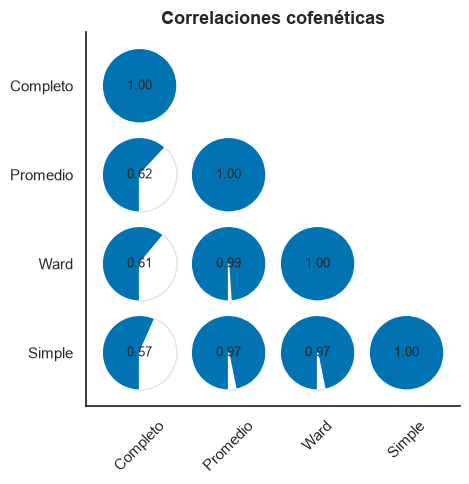

In [33]:
fig, ax = plt.subplots(figsize=(6, 5))
for i in range(len(cor_dend)):
    for j in range(i+1):
        valor = cor_dend.iloc[i, j]
        _ = ax.add_patch(Circle((j, i), 0.42, edgecolor="#DCE4E8", facecolor="white"))
        _ = ax.add_patch(Wedge((j, i), 0.42, 90, 90 + 360 * abs(valor),
                               facecolor=COLOR_BASE if valor >= 0 else COLOR_ACENTO))
        _ = ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9)
_ = ax.set(xticks=range(4), yticks=range(4), xlim=(-0.6, 3.6), ylim=(3.6, -0.6),
           title="Correlaciones cofenéticas")
_ = ax.set_xticklabels(cor_dend.columns, rotation=45)
_ = ax.set_yticklabels(cor_dend.index)
_ = ax.set_aspect("equal")
fig.tight_layout()
plt.show()

### 9. Tendencia al agrupamiento: Hopkins (diapositiva 19)

Antes de imponer un algoritmo, preguntamos si los puntos se distribuyen de forma aproximadamente uniforme o muestran tendencia a agruparse.

Para cada observación real muestreada calculamos la distancia $w_i$ a su vecino real más próximo, **excluyéndose a sí misma**. También generamos puntos uniformes dentro de la caja delimitada por las variables y calculamos su distancia $u_i$ a la observación real más próxima.

**En este cuaderno utilizamos:**

$$
H_0=\frac{\sum_i w_i}{\sum_i w_i+\sum_i u_i}.
$$

- **Cerca de 0:** los puntos reales tienden a agruparse.
- **Cerca de 0,5:** resultado compatible con uniformidad.
- **Cerca de 1:** posible regularidad o repulsión.

**Atención:** la diapositiva usa la convención contraria, $1-H_0$, donde un resultado próximo a 1 sugiere grupos. El valor depende de las variables, del escalado, de la semilla y del número de puntos muestreados; no determina por sí mismo cuántos grupos hay.

In [34]:
def hopkins(datos, n=None, random_state=12345):
    a = np.asarray(datos, dtype=float)
    m = len(a) - 1 if n is None else int(n)
    if not 1 <= m < len(a):
        raise ValueError("El tamaño de muestra debe estar entre 1 y n-1.")
    rng = np.random.default_rng(random_state)
    indices = rng.choice(len(a), m, replace=False)
    reales = cdist(a[indices], a)
    reales[np.arange(m), indices] = np.inf
    w = reales.min(axis=1)
    uniformes = rng.uniform(a.min(axis=0), a.max(axis=0), size=(m, a.shape[1]))
    u = cdist(uniformes, a).min(axis=1)
    return w.sum() / (w.sum() + u.sum())

In [35]:
hop = hopkins(iris2, n=len(iris2)-1, random_state=SEED)
hop

np.float64(0.16825871982124352)

## Ejercicio 5-1 — Vinos (solución guiada)

Aplica clustering jerárquico a `wine2.txt` para estudiar su tipología. **Antes de ejecutar las soluciones**, piensa qué podría cambiar al elegir otra distancia u otro enlace.

1. **Lectura.** Describe las escalas de los datos originales.
2. **Preparación.** Estandariza las variables y dibuja un mapa de calor.
3. **Árboles.** Cruza distancia euclídea / Manhattan con enlace completo / Ward. Ward con Manhattan puede calcularse mediante actualización de disimilitudes, pero **no** conserva la interpretación de mínima pérdida de inercia euclídea. No interpretes sus alturas como incremento de esa inercia.
4. **Particiones.** Examina los cuatro árboles y corta cada uno en $k=3$. Compara tamaños y similitud entre particiones **antes** de mirar las etiquetas conocidas.
5. **Perfiles.** Calcula la variabilidad explicada para un árbol euclídeo y compara los centros en unidades estandarizadas. ¿En qué variable difieren menos? ¿Por qué no comparar rangos en unidades distintas?

**Archivos:** `wine2.txt` contiene las variables numéricas. `wine.data.txt` contiene `Type` en el mismo orden: **reservamos `Type` para evaluación externa**, una vez construidas las particiones.

Las soluciones son ejemplos reproducibles, no una afirmación de que existan tres grupos naturales.

In [36]:
for carpeta in (Path.cwd(), *Path.cwd().parents):
    if (carpeta / "datos" / "wine2.txt").is_file():
        DATA_PATH = carpeta / "datos"
        break
else:
    raise FileNotFoundError("Abre el notebook dentro de la carpeta LaSalle_Estadistica.")

,mean,std,min,max
Alcohol,13.00,0.81,11.03,14.83
Malic.acid,2.34,1.12,0.74,5.80
Ash,2.37,0.27,1.36,3.23
AlcalinityAsh,19.49,3.34,10.60,30.00
Magnesium,99.74,14.28,70.00,162.00
Total.phenols,2.30,0.63,0.98,3.88
Flavanoids,2.03,1.00,0.34,5.08
Nonflavanoid.phenols,0.36,0.12,0.13,0.66
Proanthocyanins,1.59,0.57,0.41,3.58
ColorIntensity,5.06,2.32,1.28,13.00


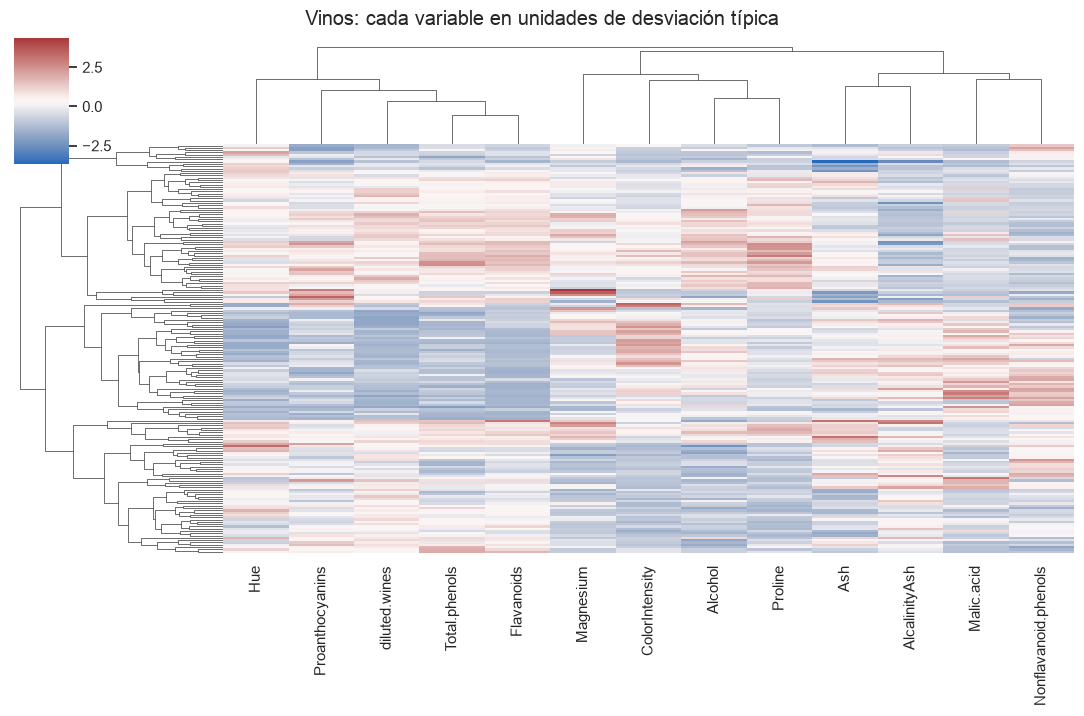

In [37]:
vinos = pd.read_csv(DATA_PATH / "wine2.txt")
tipos_vino = pd.read_csv(DATA_PATH / "wine.data.txt")["Type"]  # Solo para evaluación externa.
assert len(vinos) == len(tipos_vino) and not vinos.isna().any().any()
display(vinos.describe().T[["mean", "std", "min", "max"]].round(2))
vinos_escalados = escalar(vinos)
mapa_vino = sns.clustermap(vinos_escalados, method="complete", metric="euclidean",
                            cmap="vlag", figsize=(11, 7), yticklabels=False)
_ = mapa_vino.figure.suptitle("Vinos: cada variable en unidades de desviación típica", y=1.02)
plt.show()

,Cophenética,Tamaños (k=3)
Combinación,,
euclidean / complete,0.592,"(69, 58, 51)"
euclidean / ward,0.662,"(64, 58, 56)"
cityblock / complete,0.638,"(97, 29, 52)"
cityblock / ward,0.698,"(63, 62, 53)"


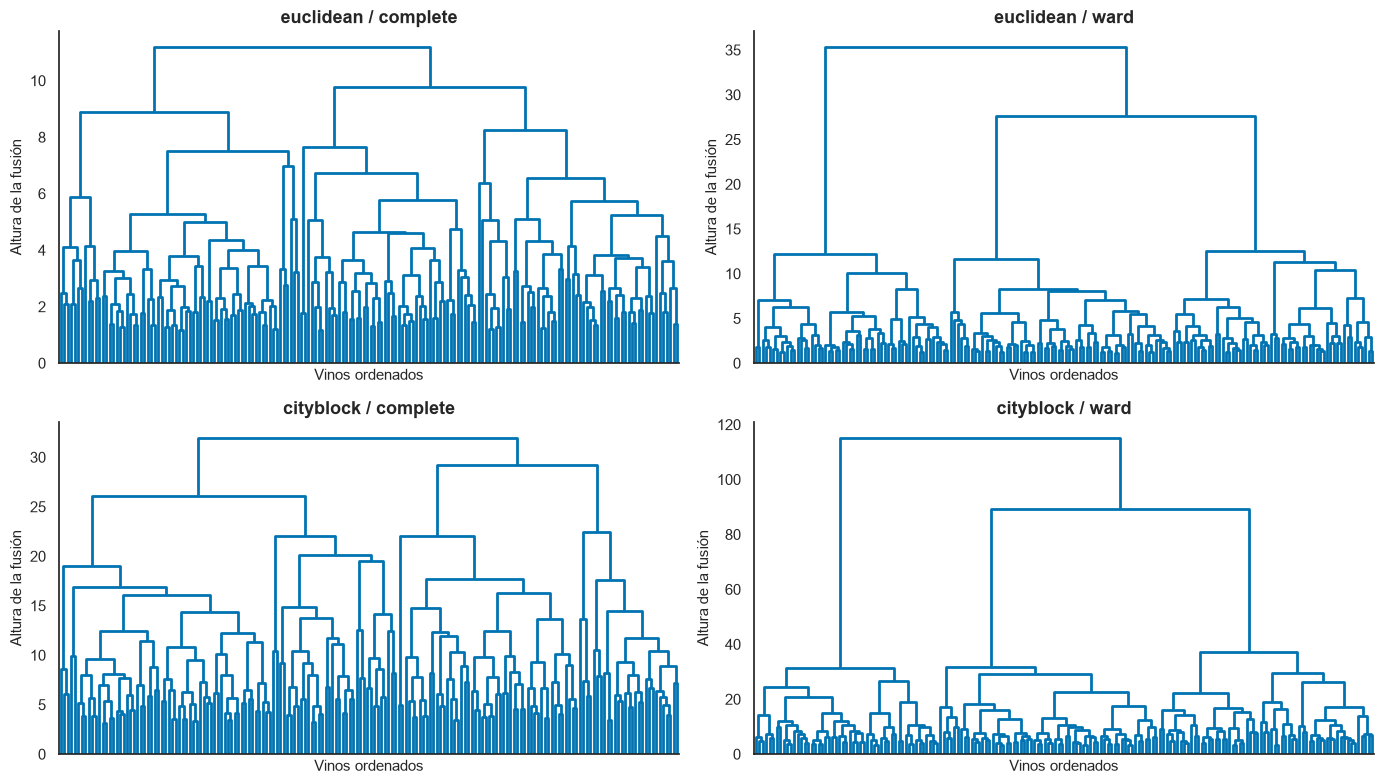

In [38]:
arboles_vino = {}
filas_vino = []
for metrica in ("euclidean", "cityblock"):
    distancia_vino = pdist(vinos_escalados, metric=metrica)
    for enlace in ("complete", "ward"):
        arbol_vino = linkage(distancia_vino, method=enlace)
        grupos_vino = renumerar(cut_tree(arbol_vino, n_clusters=3).ravel())
        nombre = f"{metrica} / {enlace}"
        arboles_vino[nombre] = (arbol_vino, grupos_vino)
        filas_vino.append({"Combinación": nombre, "Cophenética": cophenet(arbol_vino, distancia_vino)[0],
                           "Tamaños (k=3)": tuple(np.bincount(grupos_vino))})
display(pd.DataFrame(filas_vino).set_index("Combinación").round(3))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (nombre, (arbol_vino, _)) in zip(axes.flat, arboles_vino.items()):
    _ = dendrogram(arbol_vino, no_labels=True, ax=ax, color_threshold=0,
                   above_threshold_color=COLOR_BASE)
    _ = ax.set(title=nombre, xlabel="Vinos ordenados", ylabel="Altura de la fusión")
fig.tight_layout()
plt.show()

In [39]:
referencia_vino = arboles_vino["euclidean / complete"][1]
comparacion_vino = pd.Series({nombre: adjusted_rand_score(referencia_vino, grupos)
                              for nombre, (_, grupos) in arboles_vino.items()},
                             name="Rand ajustado frente a euclídea/completo")
display(comparacion_vino.round(3))
resumen_vino = resumen_particion(vinos_escalados, referencia_vino)
print(f"Variabilidad explicada por esta partición (k=3): "
      f"{resumen_vino.betweenss / resumen_vino.totss:.1%}")
perfiles_vino = vinos_escalados.groupby(referencia_vino).mean()
perfiles_vino.index.name = "Grupo"
display(perfiles_vino.round(2))
display((perfiles_vino.max() - perfiles_vino.min()).sort_values().rename(
    "Rango entre medias de grupo (en desviaciones típicas)").round(2))
# Solo después de definir la partición: inspección externa, no criterio de elección.
display(pd.crosstab(tipos_vino, referencia_vino + 1, rownames=["Tipo conocido"],
                    colnames=["Grupo descubierto"]))

euclidean / complete    1.000
euclidean / ward        0.603
cityblock / complete    0.432
cityblock / ward        0.581
Name: Rand ajustado frente a euclídea/completo, dtype: float64

Variabilidad explicada por esta partición (k=3): 35.9%


,Alcohol,Malic.acid,Ash,AlcalinityAsh,Magnesium,Total.phenols,Flavanoids,Nonflavanoid.phenols,Proanthocyanins,ColorIntensity,Hue,diluted.wines,Proline
Grupo,,,,,,,,,,,,,
0,0.50,-0.39,-0.22,-0.82,0.37,0.56,0.64,-0.52,0.42,-0.03,0.49,0.50,0.76
1,-0.72,-0.31,0.05,0.49,-0.41,0.21,0.31,0.04,0.15,-0.77,0.44,0.52,-0.55
2,0.14,0.88,0.24,0.55,-0.03,-0.99,-1.22,0.66,-0.75,0.91,-1.16,-1.27,-0.40


Ash                     0.46
Magnesium               0.78
Proanthocyanins         1.17
Nonflavanoid.phenols    1.19
Alcohol                 1.22
Malic.acid              1.27
Proline                 1.31
AlcalinityAsh           1.37
Total.phenols           1.55
Hue                     1.65
ColorIntensity          1.68
diluted.wines           1.79
Flavanoids              1.86
Name: Rango entre medias de grupo (en desviaciones típicas), dtype: float64

Grupo descubierto,1,2,3
Tipo conocido,,,
1,51,8,0
2,18,50,3
3,0,0,48


## K-means (diapositivas 23–31)

K-means busca, para un número de grupos $k$ elegido, una partición con poca **inercia intra**:

$$
\min_{C_1,\ldots,C_k}\;\sum_{g=1}^{k}\sum_{i\in C_g}\lVert x_i-\bar{x}_g\rVert^2.
$$

**Lloyd** alterna asignar cada observación al centro más próximo y recalcular los centros. **Hartigan–Wong** ensaya transferencias de observaciones que reduzcan el mismo coste. Los dos métodos pueden quedarse en un mínimo local: por eso fijamos semilla y comparamos varios inicios, conservando el menor coste **para la misma escala y el mismo $k$**.

Los centros son medias y pueden verse arrastrados por valores atípicos. Las regiones obtenidas suelen ser convexas. Tampoco conviene aplicar directamente distancia euclídea a categorías sin preparar una representación adecuada.

### Objetos del ajuste

Agrupamos Iris en tres grupos sin utilizar las especies. `cluster_centers_` contiene centros y `labels_` identificadores **arbitrarios**; `withinss`, `totss`, `betweenss` y `size` resumen la partición.

**Comprueba:** ¿la suma de las inercias de los grupos coincide con la inercia global? ¿Qué cambia si otra ejecución permuta los números de grupo sin mover una sola flor?

In [40]:
km0 = ajustar_kmeans(iris2, k=3, n_init=1, random_state=SEED)
pd.Series(km0.labels_ + 1, index=iris2.index, name="Grupo")

1      1
2      1
3      1
4      1
5      1
      ..
146    3
147    2
148    3
149    3
150    2
Name: Grupo, Length: 150, dtype: int64

In [41]:
pd.DataFrame(km0.cluster_centers_, columns=iris2.columns, index=np.arange(1, 4))

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width
1,5.006000,3.428000,1.462000,0.246000
2,5.901613,2.748387,4.393548,1.433871
3,6.850000,3.073684,5.742105,2.071053


In [42]:
resumen_km0 = resumen_particion(iris2, km0.labels_)
resumen_km0.totss       # Inercia total
resumen_km0.withinss    # Inercia intra de cada grupo
resumen_km0.inertia_    # Inercia intra global
resumen_km0.betweenss   # Inercia entre grupos
resumen_km0.size        # Tamaños
km0.n_iter_            # Iteraciones

np.float64(681.3706)

array([15.151     , 39.82096774, 23.87947368])

np.float64(78.851441426146)

np.float64(602.5191585738539)

array([50, 62, 38])

2

#### Variabilidad explicada

In [43]:
resumen_km0.betweenss / resumen_km0.totss

np.float64(0.8842752513446485)

### Número de grupos (diapositiva 28)

Al aumentar $k$, la variabilidad explicada tiende a **subir** y la inercia intra a **bajar**, incluso si los datos no contienen agrupaciones naturales.

La regla del codo busca un compromiso visual entre mejorar el ajuste y añadir más grupos. Complementa esa lectura con el tamaño de los grupos, la silhouette y su interpretación. No compares inercias absolutas calculadas en escalas distintas.

#### Regla del codo: variabilidad explicada

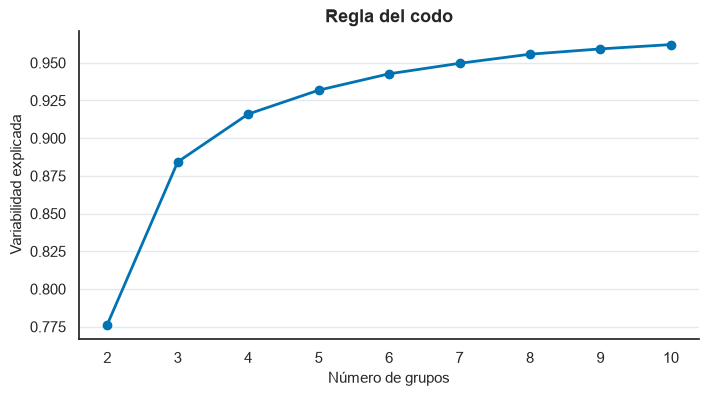

In [44]:
modelos_k = {k: ajustar_kmeans(iris2, k=k, n_init=10, random_state=SEED) for k in range(1, 11)}
VE = pd.Series({k: resumen_particion(iris2, modelos_k[k].labels_).betweenss / resumen_km0.totss
                for k in range(2, 11)}, name="Variabilidad explicada")
ax = VE.plot(marker="o", color=COLOR_BASE)
_ = ax.set(xlabel="Número de grupos", ylabel="Variabilidad explicada", title="Regla del codo")
_ = estilo_ejes(ax, cuadricula=True)
plt.show()

#### Regla del codo: inercia dentro de los grupos

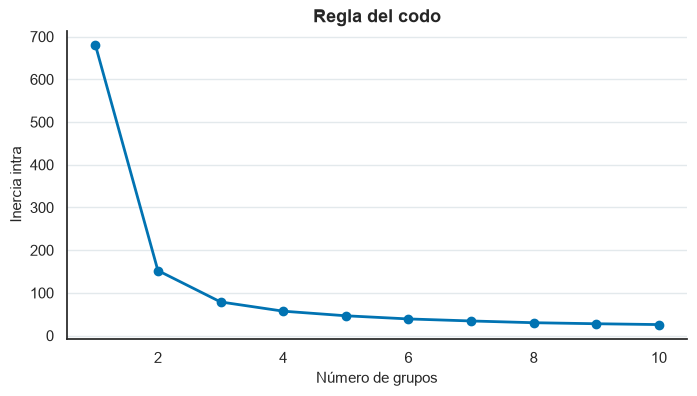

In [45]:
inercia_k = pd.Series({k: modelo.inertia_ for k, modelo in modelos_k.items()})
ax = inercia_k.plot(marker="o", color=COLOR_BASE)
_ = ax.set(xlabel="Número de grupos", ylabel="Inercia intra", title="Regla del codo")
_ = estilo_ejes(ax, cuadricula=True)
plt.show()

#### Número de grupos según los indicadores internos

In [46]:
ncluster = evaluar_indices(iris2, metodo="kmeans", min_k=2, max_k=15, random_state=SEED)
ncluster.Best_n

,k recomendado
KL,8
CH,3
CCC,3
Silhouette,2
Ratkowsky,2
PointBiserial,2
Dunn,11
Cindex,8
DB,2
McClain,2


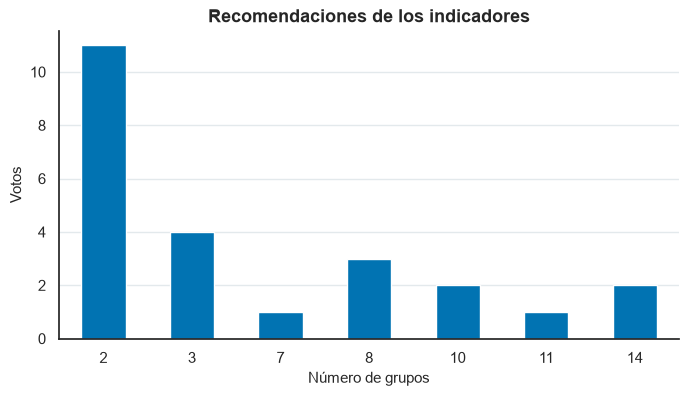

In [47]:
ax = ncluster.Votes.plot.bar(rot=0, color=COLOR_BASE)
_ = ax.set(xlabel="Número de grupos", ylabel="Votos", title="Recomendaciones de los indicadores")
_ = estilo_ejes(ax, cuadricula=True)
plt.show()

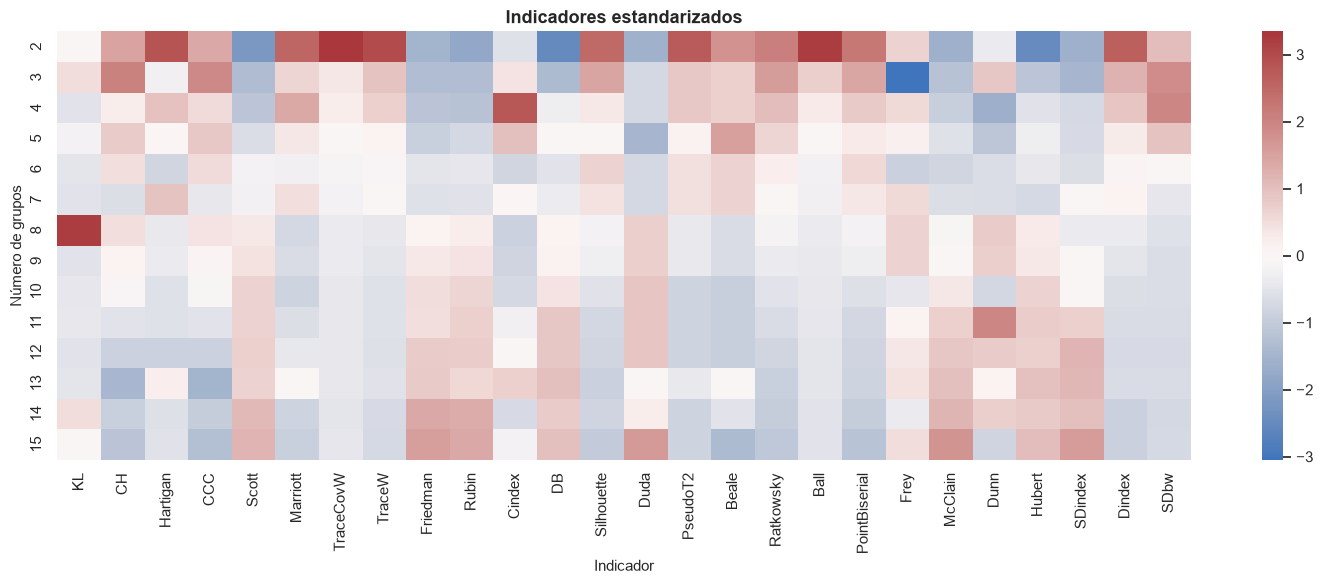

In [48]:
indices_escalados = escalar(ncluster.All_index)
fig, ax = plt.subplots(figsize=(15, 6))
_ = sns.heatmap(indices_escalados, cmap="vlag", center=0, ax=ax)
_ = ax.set(title="Indicadores estandarizados", xlabel="Indicador", ylabel="Número de grupos")
fig.tight_layout()
plt.show()

### Representación: tres grupos

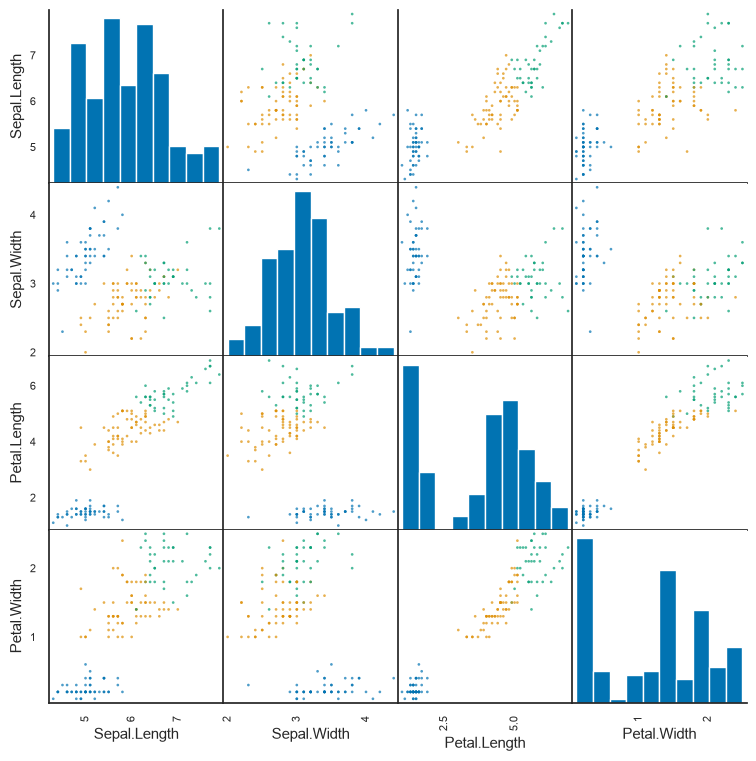

In [49]:
km3 = ajustar_kmeans(iris2, k=3, n_init=10, random_state=SEED)
pares_coloreados(iris2, km3.labels_)

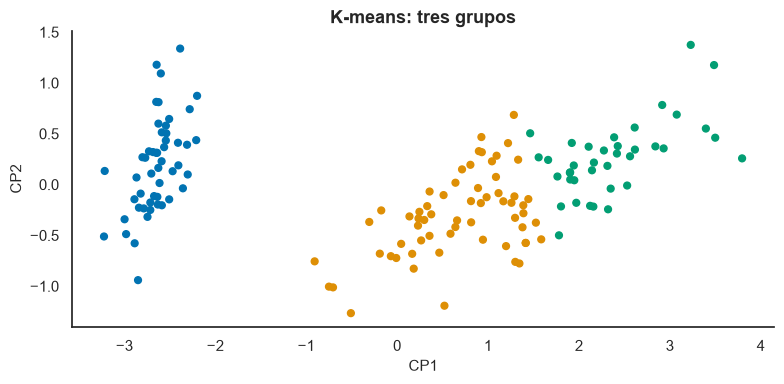

In [50]:
pr_comp = PCA().fit(iris2)
coordenadas = pr_comp.transform(iris2)
x, y = coordenadas[:, 0], coordenadas[:, 1]
fig, ax = plt.subplots()
_ = ax.scatter(x, y, c=km3.labels_, cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=24)
_ = ax.set(xlabel="CP1", ylabel="CP2", title="K-means: tres grupos")
fig.tight_layout()
plt.show()

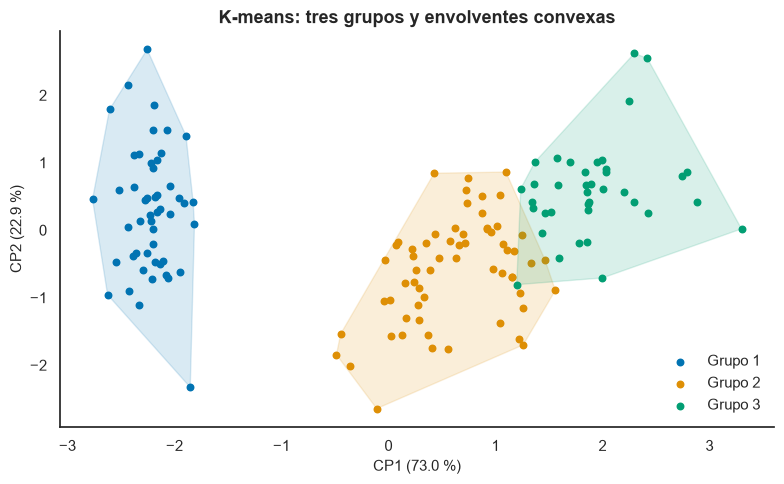

In [51]:
representar_clusters(iris2, km3.labels_, titulo="K-means: tres grupos y envolventes convexas")

#### Tres dimensiones: color por grupo y símbolo por especie. Cambia el ángulo de visión.

In [52]:
def iris_3d(angulo):
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")
    for especie, marcador in enumerate(["o", "s", "^"]):
        mascara = dataset.target == especie
        ax.scatter(iris2.loc[mascara, "Sepal.Length"], iris2.loc[mascara, "Sepal.Width"],
                   iris2.loc[mascara, "Petal.Length"], c=km3.labels_[mascara], cmap=MAPA_GRUPOS,
                   vmin=-0.5, vmax=9.5, marker=marcador, label=dataset.target_names[especie])
    for fila, grupo in zip(iris2.to_numpy(), km3.labels_):
        ax.plot([fila[0], fila[0]], [fila[1], fila[1]], [0, fila[2]],
                color=COLORES_GRUPO[int(grupo) % 10], alpha=0.15, linewidth=0.5)
    ax.set(xlabel="Sepal.Length", ylabel="Sepal.Width", zlabel="Petal.Length")
    ax.view_init(elev=20, azim=angulo)
    ax.legend(frameon=False)
    fig.tight_layout()
    display(widgets.HTML(value=imagen_control(fig, f"Iris en tres dimensiones, ángulo {angulo}°")))

In [53]:
control_3d = widgets.interactive(
    iris_3d,
    angulo=widgets.IntSlider(value=60, min=0, max=180, step=5, description="Ángulo", continuous_update=False),
)
display(panel_interactivo("Gira la representación 3D de Iris", control_3d))

### Representación: dos grupos

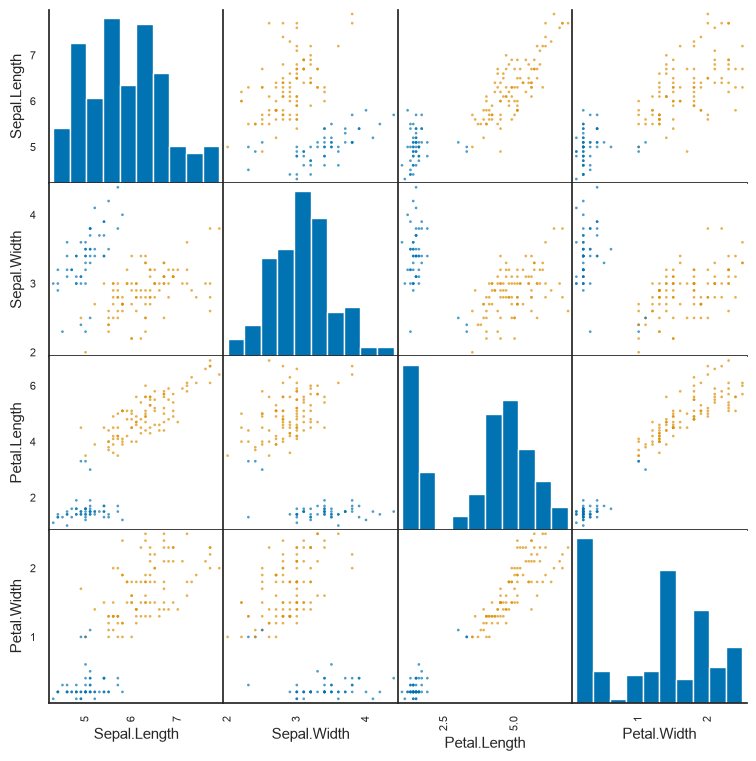

In [54]:
km2 = ajustar_kmeans(iris2, k=2, n_init=10, random_state=SEED)
pares_coloreados(iris2, km2.labels_)

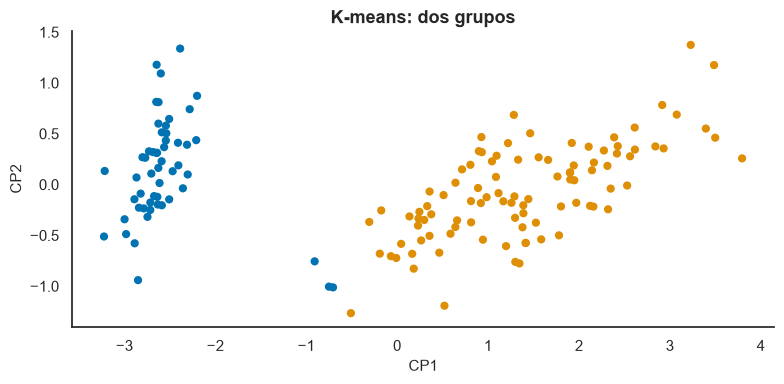

In [55]:
fig, ax = plt.subplots()
_ = ax.scatter(x, y, c=km2.labels_, cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=24)
_ = ax.set(xlabel="CP1", ylabel="CP2", title="K-means: dos grupos")
fig.tight_layout()
plt.show()

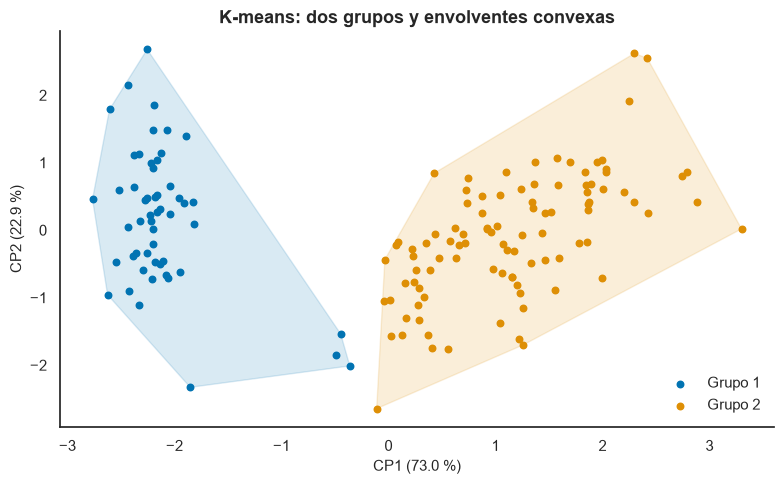

In [56]:
representar_clusters(iris2, km2.labels_, titulo="K-means: dos grupos y envolventes convexas")

#### Explorar k, los inicios y el algoritmo

In [57]:
def explorar_kmeans(k, inicios, algoritmo):
    modelo = ajustar_kmeans(iris2, k, n_init=inicios, algoritmo=algoritmo, random_state=SEED)
    grafico = representar_clusters(iris2, modelo.labels_, titulo=f"K-means: {k} grupos", mostrar=False)
    display(widgets.HTML(value=grafico))
    resumen = resumen_particion(iris2, modelo.labels_)
    display(pd.Series({"Inercia intra": modelo.inertia_, "Variabilidad explicada": resumen.betweenss / resumen.totss,
                       "Silhouette": silhouette_score(iris2, modelo.labels_)}))

In [58]:
control_kmeans = widgets.interactive(
    explorar_kmeans,
    k=widgets.IntSlider(value=3, min=2, max=8, description="Grupos", continuous_update=False),
    inicios=widgets.SelectionSlider(options=[1, 5, 10], value=10, description="Inicios", continuous_update=False),
    algoritmo=widgets.Dropdown(options=[("Hartigan–Wong", "hartigan-wong"), ("Lloyd", "lloyd")], description="Algoritmo"),
)
display(panel_interactivo("Compara los ajustes de k-means", control_kmeans))

## K-medoides (diapositivas 33–34)

A diferencia de k-means, un **medoide es una observación real** que representa al grupo. PAM trabaja con distancias a medoides en vez de distancias cuadráticas a medias:

$$
\min_{m_1,\ldots,m_k\;\text{observaciones}}\;\sum_{i=1}^{n}\min_{g=1,\ldots,k}d(x_i,m_g).
$$

La fase **BUILD** escoge medoides iniciales y **SWAP** prueba intercambios que reduzcan ese coste. La suma de distancias de PAM **no es la inercia cuadrática** de k-means: no compares sus valores numéricos directamente. PAM admite otras disimilitudes y puede ser menos sensible a atípicos, pero no es inmune a ellos.

**CLARA** repite PAM en muestras y evalúa los medoides encontrados en el conjunto completo. Reduce el coste computacional, pero depende de que las muestras representen los grupos.

**Pregunta:** ¿qué sucedería si un grupo pequeño faltase de todas las muestras?

In [59]:
def pam(datos, k, distancias=None, max_iter=100):
    a = np.asarray(datos, dtype=float)
    D = squareform(pdist(a)) if distancias is None else np.asarray(distancias)
    if not 1 <= k < len(a):
        raise ValueError("k debe ser menor que el número de observaciones.")
    # BUILD: añadir observaciones reales que reduzcan la distancia total.
    medoides = [int(D.sum(axis=0).argmin())]
    while len(medoides) < k:
        cercana = D[:, medoides].min(axis=1)
        costes = np.minimum(D, cercana[:, None]).sum(axis=0)
        costes[medoides] = np.inf
        medoides.append(int(costes.argmin()))
    # SWAP: buscar el mejor intercambio de un medoide por otra observación.
    historial = []
    for iteracion in range(max_iter):
        actuales = D[:, medoides]
        asignacion = actuales.argmin(axis=1)
        primera = actuales.min(axis=1)
        segunda = np.partition(actuales, 1, axis=1)[:, 1] if k > 1 else np.full(len(a), np.inf)
        coste_actual = primera.sum()
        historial.append(coste_actual)
        mejor = (coste_actual, None, None)
        for j in range(k):
            base = np.where(asignacion == j, segunda, primera)
            costes = np.minimum(D, base[:, None]).sum(axis=0)
            costes[medoides] = np.inf
            candidato = int(costes.argmin())
            if costes[candidato] < mejor[0] - 1e-9:
                mejor = (costes[candidato], j, candidato)
        if mejor[1] is None:
            break
        medoides[mejor[1]] = mejor[2]
    etiquetas = D[:, medoides].argmin(axis=1)
    return SimpleNamespace(labels_=etiquetas, medoid_indices_=np.array(medoides),
                           cluster_centers_=a[medoides], inertia_=D[:, medoides].min(axis=1).sum(),
                           history_=np.array(historial), n_iter_=iteracion + 1)

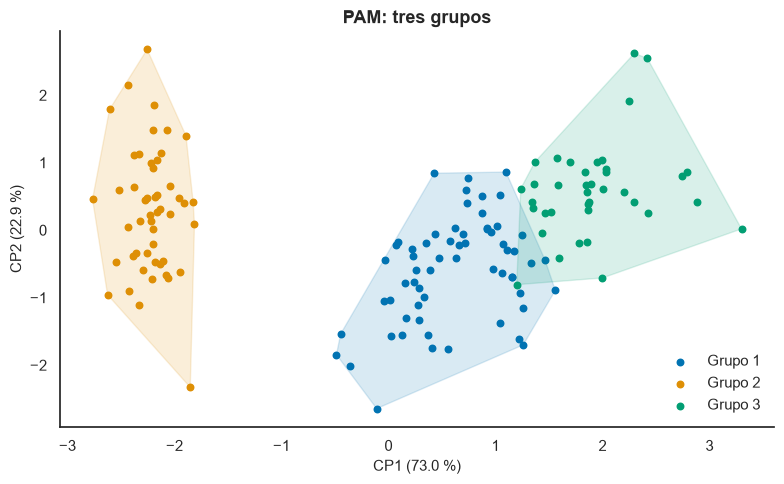

In [60]:
kmedoids3 = pam(iris2, k=3)
representar_clusters(iris2, kmedoids3.labels_, titulo="PAM: tres grupos")

#### Similitud entre las particiones de k-means y PAM: índice de Rand ajustado

In [61]:
adjusted_rand_score(km3.labels_, kmedoids3.labels_)

1.0

#### Similitud entre k-means y las especies originales

In [62]:
adjusted_rand_score(km3.labels_, iris["Species"])

0.7302382722834697

## Grupos no convexos

Generamos 500 observaciones en un disco de radio 1 y otras 500 en una corona de radios entre 2 y 3.
El radio se obtiene de una distribución uniforme, tal como plantea el ejemplo.

In [63]:
n = 500
rng = np.random.default_rng(SEED)
r1 = rng.uniform(0, 1, n)
alfa1 = rng.uniform(0, 2 * np.pi, n)
x1, y1 = r1 * np.cos(alfa1), r1 * np.sin(alfa1)
r2 = rng.uniform(2, 3, n)
alfa2 = rng.uniform(0, 2 * np.pi, n)
x2, y2 = r2 * np.cos(alfa2), r2 * np.sin(alfa2)
df_anillos = pd.DataFrame({"x": np.r_[x1, x2], "y": np.r_[y1, y2]})
df_anillos_escalado = escalar(df_anillos)

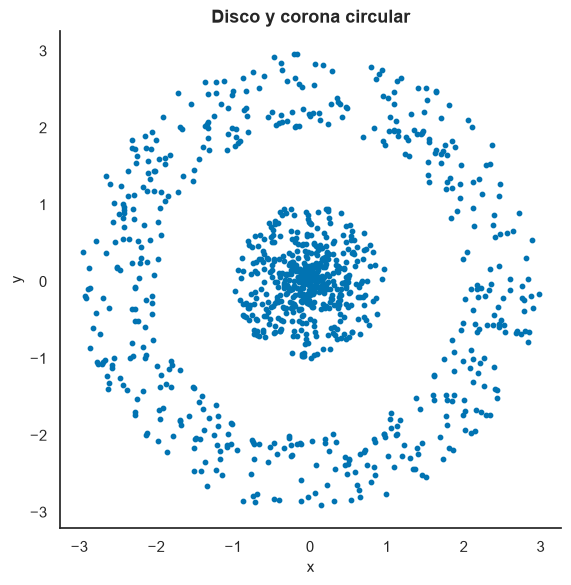

In [64]:
fig, ax = plt.subplots(figsize=(6, 6))
_ = ax.scatter(df_anillos["x"], df_anillos["y"], s=10, color=COLOR_BASE)
_ = ax.set(xlabel="x", ylabel="y", title="Disco y corona circular")
_ = ax.set_aspect("equal")
fig.tight_layout()
plt.show()

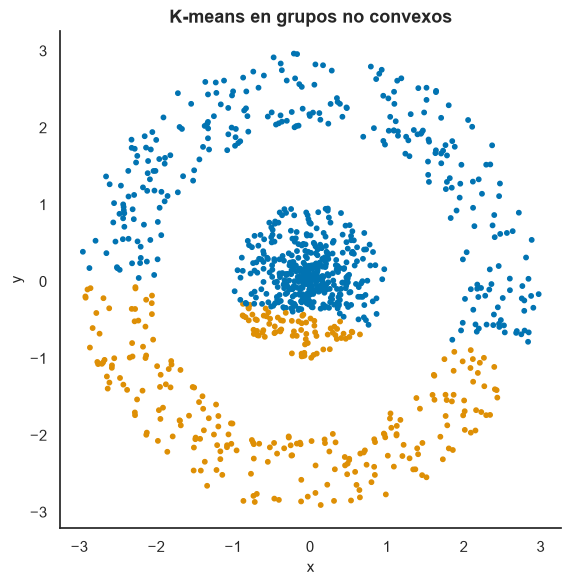

In [65]:
km_anillos = ajustar_kmeans(df_anillos_escalado, k=2, n_init=1, random_state=SEED)
fig, ax = plt.subplots(figsize=(6, 6))
_ = ax.scatter(df_anillos["x"], df_anillos["y"], c=km_anillos.labels_,
               cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=10)
_ = ax.set(title="K-means en grupos no convexos", xlabel="x", ylabel="y")
_ = ax.set_aspect("equal")
fig.tight_layout()
plt.show()

### K-means con kernel

Un grupo anular rodea al disco: un centro euclídeo puede quedar cerca de puntos que en realidad pertenecen a **dos grupos distintos**. Para explorar este límite de k-means, usamos un kernel gaussiano:

$$
K(x_i,x_j)=\exp\!\left(-\gamma\lVert x_i-x_j\rVert^2\right).
$$

El kernel asigna mayor similitud a puntos próximos. **K-means con kernel** actualiza los grupos usando distancias a centros en el espacio implícito definido por esa similitud; no equivale a aplicar k-means euclídeo directamente a las coordenadas originales. Aquí la inicialización utiliza una representación espectral.

Con $\gamma$ pequeño, incluso puntos alejados se parecen; con $\gamma$ grande, la similitud disminuye más rápido. El control deja explorar el efecto sin modificar los resultados fijos de Iris.

**Pregunta:** ¿qué forma geométrica separa mal un método basado en centros de las coordenadas originales?

In [66]:
def kernel_kmeans(datos, k=2, gamma=2.0, random_state=12345, max_iter=100):
    a = np.asarray(datos, dtype=float)
    K = np.exp(-gamma * squareform(pdist(a, metric="sqeuclidean")))
    pesos = np.sqrt(K.sum(axis=1))
    normalizada = K / np.outer(pesos, pesos)
    with threadpool_limits(limits=1):
        _, vectores = eigh(normalizada, subset_by_index=[len(a) - k, len(a) - 1])
        vectores = vectores / np.linalg.norm(vectores, axis=1, keepdims=True)
        etiquetas = KMeans(k, n_init=10, random_state=random_state).fit_predict(vectores)
    historial = []
    for iteracion in range(max_iter):
        distancias = np.empty((len(a), k))
        for grupo in range(k):
            miembros = np.flatnonzero(etiquetas == grupo)
            if not len(miembros):
                raise ValueError("El kernel ha producido un grupo vacío; cambia gamma.")
            distancias[:, grupo] = np.diag(K) - 2 * K[:, miembros].mean(axis=1) + K[np.ix_(miembros, miembros)].mean()
        nuevas = distancias.argmin(axis=1)
        historial.append(float(distancias[np.arange(len(a)), etiquetas].sum()))
        if np.array_equal(nuevas, etiquetas):
            break
        if len(np.unique(nuevas)) < k:
            break
        etiquetas = nuevas
    return SimpleNamespace(labels_=etiquetas, history_=np.array(historial), n_iter_=iteracion + 1)

In [67]:
kk = kernel_kmeans(df_anillos_escalado, k=2, gamma=2.0, random_state=SEED)

def explorar_kernel(gamma):
    resultado = kernel_kmeans(df_anillos_escalado, k=2, gamma=gamma, random_state=SEED)
    fig, ax = plt.subplots(figsize=(6, 6))
    _ = ax.scatter(df_anillos["x"], df_anillos["y"], c=resultado.labels_,
                   cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=10)
    titulo = f"K-means con kernel gaussiano: gamma = {gamma:.2f}"
    _ = ax.set(xlabel="x", ylabel="y", title=titulo)
    _ = ax.set_aspect("equal")
    fig.tight_layout()
    display(widgets.HTML(value=imagen_control(fig, titulo)))

In [68]:
control_kernel = widgets.interactive(
    explorar_kernel,
    gamma=widgets.FloatSlider(value=2.0, min=0.5, max=4, step=0.25, description="Gamma", continuous_update=False),
)
display(panel_interactivo("Explora la anchura del kernel", control_kernel))

## Valores atípicos

Generamos 1000 observaciones en dos grupos y añadimos tres puntos muy alejados, alrededor de 100 000 en ambos ejes. Para que los grupos y los atípicos puedan verse en una misma figura, representamos los datos con **ejes logarítmicos**.

Comparamos k-means, PAM y CLARA. K-means utiliza medias; PAM utiliza observaciones representativas, y CLARA ajusta PAM sobre muestras antes de evaluar sus medoides en todos los datos.

**Observa:** ¿cambian los grupos más que su apariencia cuando modificamos el número de atípicos? El gráfico en escala logarítmica **no** significa que los algoritmos ajusten sobre datos logarítmicos: aquí reciben los datos originales.

In [69]:
def clara(datos, k, samples=5, sampsize=None, random_state=12345):
    a = np.asarray(datos, dtype=float)
    rng = np.random.default_rng(random_state)
    tamano = min(len(a), 40 + 2 * k) if sampsize is None else min(len(a), sampsize)
    if tamano <= k:
        raise ValueError("El tamaño de muestra debe ser mayor que k.")
    mejor = None
    for _ in range(samples):
        conservar = np.array([], dtype=int) if mejor is None else mejor.medoid_indices_
        candidatos = np.setdiff1d(np.arange(len(a)), conservar)
        indices = np.r_[conservar, rng.choice(candidatos, tamano - len(conservar), replace=False)]
        local = pam(a[indices], k)
        medoides = indices[local.medoid_indices_]
        distancias = cdist(a, a[medoides])
        coste = distancias.min(axis=1).sum()
        if mejor is None or coste < mejor.inertia_:
            mejor = SimpleNamespace(labels_=distancias.argmin(axis=1), medoid_indices_=medoides,
                                     cluster_centers_=a[medoides], inertia_=coste)
    return mejor

In [70]:
def generar_atipicos(nout=3):
    rng = np.random.default_rng(SEED)
    n = 1000
    x1 = np.r_[rng.normal(10, 1, n//2), rng.normal(100, 1, n//2), rng.normal(10**5, 1, nout)]
    x2 = np.r_[rng.normal(10, 1, n), rng.normal(10**5, 1, nout)]
    return pd.DataFrame({"x1": x1, "x2": x2})

df_atipicos = generar_atipicos(nout=3)
km_atipicos = ajustar_kmeans(df_atipicos, k=2, n_init=1, random_state=SEED)
pam_atipicos = pam(df_atipicos, k=2)
clara_atipicos = clara(df_atipicos, k=2, random_state=SEED)

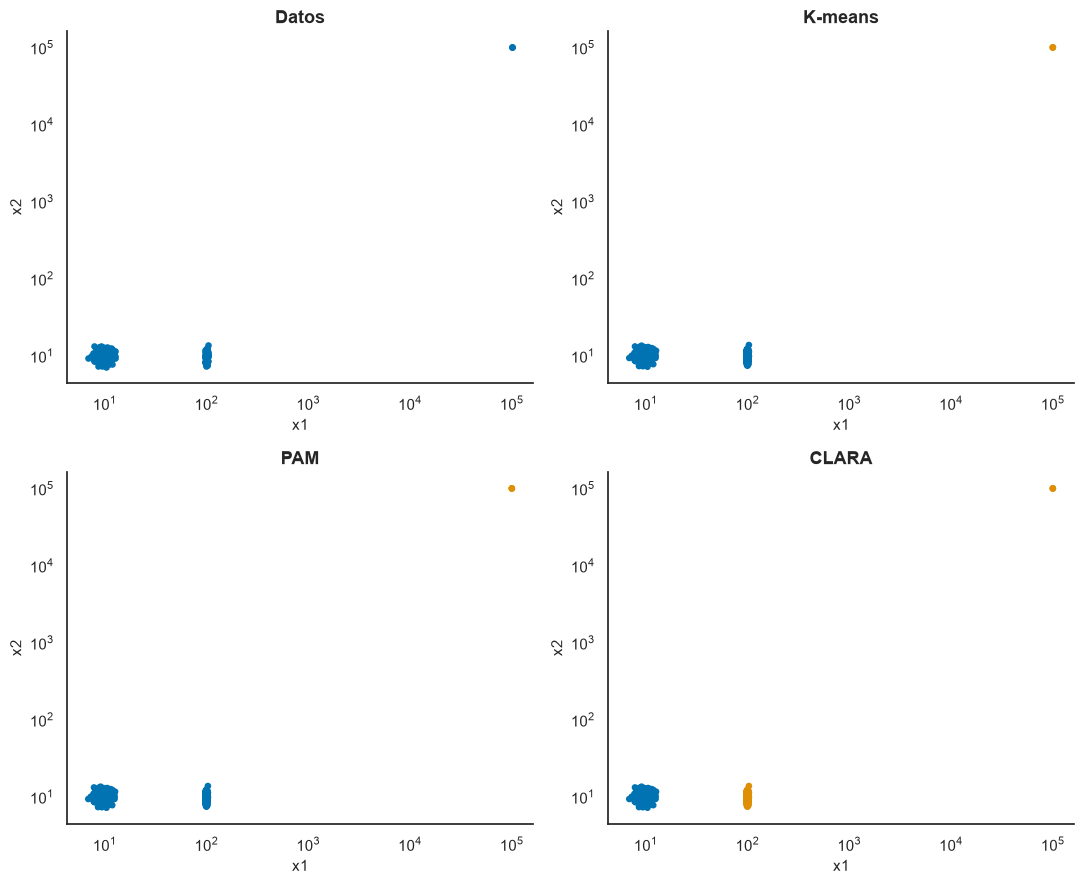

In [71]:
def dibujar_atipicos(tabla, modelos, mostrar=True):
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for ax, (nombre, grupos) in zip(axes.flat, modelos.items()):
        if grupos is None:
            _ = ax.scatter(tabla["x1"], tabla["x2"], color=COLOR_BASE, s=14)
        else:
            _ = ax.scatter(tabla["x1"], tabla["x2"], c=grupos,
                           cmap=MAPA_GRUPOS, vmin=-0.5, vmax=9.5, s=14)
        _ = ax.set(xscale="log", yscale="log", xlabel="x1", ylabel="x2", title=nombre)
    fig.tight_layout()
    if not mostrar:
        return imagen_control(fig, "Comparación de datos, k-means, PAM y CLARA con valores atípicos")
    plt.show()

dibujar_atipicos(df_atipicos, {"Datos": None, "K-means": km_atipicos.labels_,
                              "PAM": pam_atipicos.labels_, "CLARA": clara_atipicos.labels_})

#### Explorar el número de observaciones atípicas

In [72]:
def explorar_atipicos(numero):
    tabla = generar_atipicos(nout=numero)
    km = ajustar_kmeans(tabla, k=2, n_init=1, random_state=SEED)
    med = pam(tabla, k=2)
    muestra = clara(tabla, k=2, random_state=SEED)
    grafico = dibujar_atipicos(tabla, {"Datos": None, "K-means": km.labels_,
                                     "PAM": med.labels_, "CLARA": muestra.labels_}, mostrar=False)
    display(widgets.HTML(value=grafico))

In [73]:
control_atipicos = widgets.interactive(
    explorar_atipicos,
    numero=widgets.IntSlider(value=3, min=0, max=8, description="Atípicos", continuous_update=False),
)
display(panel_interactivo("Explora el efecto de los valores atípicos", control_atipicos))

## Ejercicio 5-2 — Clientes de un mayorista (solución guiada)

**Intenta resolver cada apartado antes de ejecutar su solución.** Las seis variables representan gasto anual en productos frescos (`Fresh`), leche (`Milk`), comestibles (`Grocery`), congelados (`Frozen`), detergentes (`Detergents_Paper`) y delicatessen (`Delicassen`).

Aquí **no hay una clase conocida**. Evaluaremos las particiones mediante métricas internas y describiremos los grupos con sus perfiles de gasto. Cada transformación responde a una pregunta distinta: evita comparar inercias obtenidas en escalas diferentes.

### 1. Lectura

Lee `Wholesale customers data.csv` desde `DATA_PATH`. Aunque el archivo se llama CSV, sus columnas están **separadas por tabuladores**. Comprueba el número de observaciones, los tipos de datos y los valores ausentes.

In [74]:
mayorista = pd.read_csv(DATA_PATH / "Wholesale customers data.csv", sep="\t")
assert mayorista.shape[1] == 6 and not mayorista.isna().any().any()
display(mayorista.head())
display(mayorista.dtypes)
print(f"{len(mayorista)} clientes sin valores ausentes")

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

440 clientes sin valores ausentes


### 2. Descriptiva y estandarización

Compara la dispersión y la asimetría de los gastos. Unos pocos importes muy altos pueden dominar las medias y las distancias euclídeas.

En esta solución aplicamos primero una transformación logarítmica y después estandarizamos cada columna:

$$
z_{ij}=\frac{\log(1+x_{ij})-\overline{\log(1+x_{\cdot j})}}{s_j},
$$

con $s_j$ igual a la desviación típica de la variable $j$ **después del logaritmo**. Así las diferencias relativas pesan más que las diferencias absolutas.

**Pregunta:** ¿qué cambiaría al agrupar directamente los gastos originales? Conservamos esos importes para interpretar los perfiles al final; `mayorista_x` se utiliza solo para ajustar los modelos.

In [75]:
display(mayorista.describe().T[["mean", "50%", "std", "max"]].round(1))
mayorista_x = escalar(np.log1p(mayorista))
assert np.isfinite(mayorista_x.to_numpy()).all()
display(mayorista_x.describe().loc[["mean", "std"]].round(3))

,mean,50%,std,max
Fresh,12000.3,8504.0,12647.3,112151.0
Milk,5796.3,3627.0,7380.4,73498.0
Grocery,7951.3,4755.5,9503.2,92780.0
Frozen,3071.9,1526.0,4854.7,60869.0
Detergents_Paper,2881.5,816.5,4767.9,40827.0
Delicassen,1524.9,965.5,2820.1,47943.0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
mean,0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


### 3. Número de grupos

Calcula la inercia para $k=2,\ldots,10$ con **diez inicios por valor de $k$**. Busca si la curva muestra un codo: un descenso que se atenúa al aumentar el número de grupos.

Como segundo criterio calcula la **silhouette media** usando las mismas variables transformadas. Su máximo y el codo pueden diferir; ninguno valida por sí solo la utilidad de los grupos.

En el apartado siguiente estudiaremos $k=5,6,7,8$ como propone el ejercicio, incluso si este gráfico favorece otros valores. **No** elijas $k$ por un p-valor inexistente.

,Inercia intra,Silhouette media
2,1839.873,0.290
3,1549.860,0.258
4,1383.723,0.188
5,1264.396,0.196
6,1171.733,0.193
7,1084.251,0.195
8,1021.844,0.191
9,970.080,0.192
10,930.500,0.183


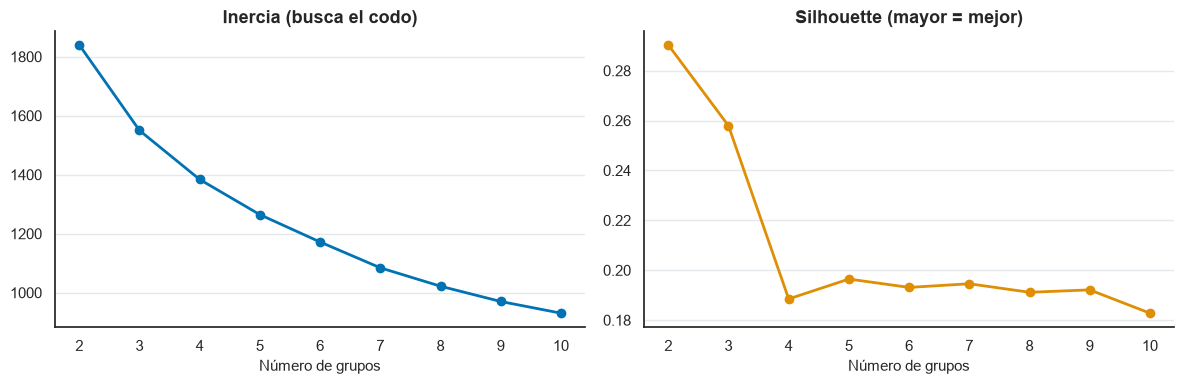

In [76]:
candidatos_mayorista = {}
for k in range(2, 11):
    candidatos_mayorista[k] = ajustar_kmeans(mayorista_x, k, n_init=10,
                                            random_state=SEED, algoritmo="lloyd")
resumen_mayorista = pd.DataFrame({
    "Inercia intra": {k: mod.inertia_ for k, mod in candidatos_mayorista.items()},
    "Silhouette media": {k: silhouette_score(mayorista_x, mod.labels_)
                         for k, mod in candidatos_mayorista.items()},
})
display(resumen_mayorista.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
_ = resumen_mayorista["Inercia intra"].plot(ax=ejes[0], marker="o", color=COLOR_BASE)
_ = resumen_mayorista["Silhouette media"].plot(ax=ejes[1], marker="o", color=COLOR_ACENTO)
for eje, titulo in zip(ejes, ["Inercia (busca el codo)", "Silhouette (mayor = mejor)"]):
    _ = eje.set(xlabel="Número de grupos", title=titulo)
    _ = estilo_ejes(eje, cuadricula=True)
fig.tight_layout()
plt.show()

### 4. Cuatro ajustes de k-means

Para cada $k$ entre **5 y 8**, compara cuatro sistemas sobre los **mismos datos transformados**:

1. Lloyd con un inicio.
2. Hartigan–Wong con un inicio.
3. Hartigan–Wong con diez inicios.
4. Un árbol Ward euclídeo seguido de Hartigan–Wong, inicializado en los centros de su partición.

Evalúa cada resultado con **Dunn**, que compara separación mínima y diámetro máximo interno, y **silhouette**, que resume cohesión y separación media. Estos métodos minimizan **inercia**, no directamente Dunn ni silhouette: los índices sirven para comparar los resultados, no para dirigir su ajuste.

**Para pensar:** ¿coinciden los índices al elegir $k$? Un inicio puede quedar atrapado en un mínimo local, y dos métodos con el mismo $k$ pueden devolver etiquetas diferentes. Si algún grupo es pequeño, Dunn puede depender mucho de una sola observación.

In [77]:
arbol_mayorista = linkage(pdist(mayorista_x), method="ward")
distancias_mayorista = squareform(pdist(mayorista_x))
resultados_sistemas = {}
filas_indicadores = []
for k in range(5, 9):
    grupos_arbol = renumerar(cut_tree(arbol_mayorista, n_clusters=k).ravel())
    centros_arbol = np.array([mayorista_x.to_numpy()[grupos_arbol == j].mean(axis=0)
                              for j in range(k)])
    sistemas = {
        "Lloyd (1)": ajustar_kmeans(mayorista_x, k, n_init=1, random_state=SEED,
                                     algoritmo="lloyd"),
        "Hartigan (1)": ajustar_kmeans(mayorista_x, k, n_init=1, random_state=SEED),
        "Hartigan (10)": ajustar_kmeans(mayorista_x, k, n_init=10, random_state=SEED),
        "Jerárquico + Hartigan": ajustar_kmeans(mayorista_x, k, init=centros_arbol,
                                                  random_state=SEED),
    }
    for nombre, modelo in sistemas.items():
        etiquetas = modelo.labels_
        resultados_sistemas[(k, nombre)] = etiquetas
        filas_indicadores.append({"k": k, "Sistema": nombre,
                                  "Dunn": indice_dunn(distancias_mayorista, etiquetas),
                                  "Silhouette": silhouette_score(distancias_mayorista, etiquetas,
                                                                 metric="precomputed"),
                                  "Inercia": modelo.inertia_})
indicadores_mayorista = pd.DataFrame(filas_indicadores).set_index(["k", "Sistema"])
display(indicadores_mayorista.round(3))
print("Mejor k entre 5–8 para cada sistema e índice (no necesariamente iguales):")
display(pd.DataFrame({indice: indicadores_mayorista[indice].unstack("Sistema").idxmax()
                      for indice in ("Dunn", "Silhouette")}))

Dunn  Silhouette   Inercia
k Sistema                                           
5 Lloyd (1)              0.048       0.195  1265.021
  Hartigan (1)           0.048       0.201  1265.336
  Hartigan (10)          0.033       0.192  1263.198
  Jerárquico + Hartigan  0.046       0.187  1286.547
6 Lloyd (1)              0.029       0.189  1179.051
  Hartigan (1)           0.053       0.183  1174.281
  Hartigan (10)          0.046       0.195  1171.789
  Jerárquico + Hartigan  0.046       0.195  1171.789
7 Lloyd (1)              0.059       0.186  1092.607
  Hartigan (1)           0.035       0.157  1118.850
  Hartigan (10)          0.035       0.189  1084.782
  Jerárquico + Hartigan  0.050       0.198  1093.014
8 Lloyd (1)              0.053       0.191  1021.844
  Hartigan (1)           0.043       0.165  1040.122
  Hartigan (10)          0.053       0.199  1018.935
  Jerárquico + Hartigan  0.053       0.197  1018.946

Mejor k entre 5–8 para cada sistema e índice (no necesariamente iguales):


,Dunn,Silhouette
Sistema,,
Hartigan (1),6,5
Hartigan (10),8,8
Jerárquico + Hartigan,8,7
Lloyd (1),7,5


### 5. Similitud de las particiones (diapositiva 37)

Para **2** y **5** grupos, compara Lloyd con un inicio y Hartigan–Wong con diez inicios. Usa la misma semilla, **1234**, en ambos ajustes.

El **índice de Rand ajustado (ARI)** compara pares de observaciones y corrige el acuerdo esperado por azar. Vale **1** para dos particiones idénticas, aunque permutes los números de grupo; suele estar cerca de **0** para una coincidencia aproximadamente aleatoria y también puede ser negativo.

No lo confundas con el Rand sin ajustar ni con la exactitud de clasificación. Un acuerdo alto entre métodos **no** demuestra que los segmentos sean útiles.

In [78]:
comparacion_ari = {}
for k in (2, 5):
    lloyd = ajustar_kmeans(mayorista_x, k, algoritmo="lloyd", n_init=1, random_state=1234)
    hartigan = ajustar_kmeans(mayorista_x, k, n_init=10, random_state=1234)
    comparacion_ari[k] = adjusted_rand_score(lloyd.labels_, hartigan.labels_)
display(pd.Series(comparacion_ari, name="Rand ajustado: Lloyd (1) / Hartigan (10)").round(3))

2    0.991
5    0.549
Name: Rand ajustado: Lloyd (1) / Hartigan (10), dtype: float64

### 6. Describir los grupos

Como **ejemplo**, usa la partición Hartigan–Wong con diez inicios y $k=5$ calculada arriba. Es una elección didáctica para comparar perfiles, no un óptimo demostrado; prueba otra si tus criterios justifican cambiarla. Muestra tamaños, medianas en **gasto original** y diagramas de caja en **escala $\log(1+x)$** para distinguir grupos sin que unos pocos importes extremos oculten el resto. Los números de grupo son arbitrarios y las diferencias descriptivas no prueban causas.

Tamaño de cada grupo:


Grupo
1    100
2    100
3     98
4     54
5     88
Name: count, dtype: int64

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Grupo,,,,,,
1,7701.0,9770.0,13576.0,1606.0,5495.0,1811.0
2,18429.0,2836.0,3430.0,5858.0,504.0,1548.0
3,8304.0,3197.0,3400.0,828.0,556.0,796.0
4,992.0,7244.0,11207.0,279.0,4918.0,272.0
5,7814.0,896.0,1463.0,2108.0,184.0,375.0


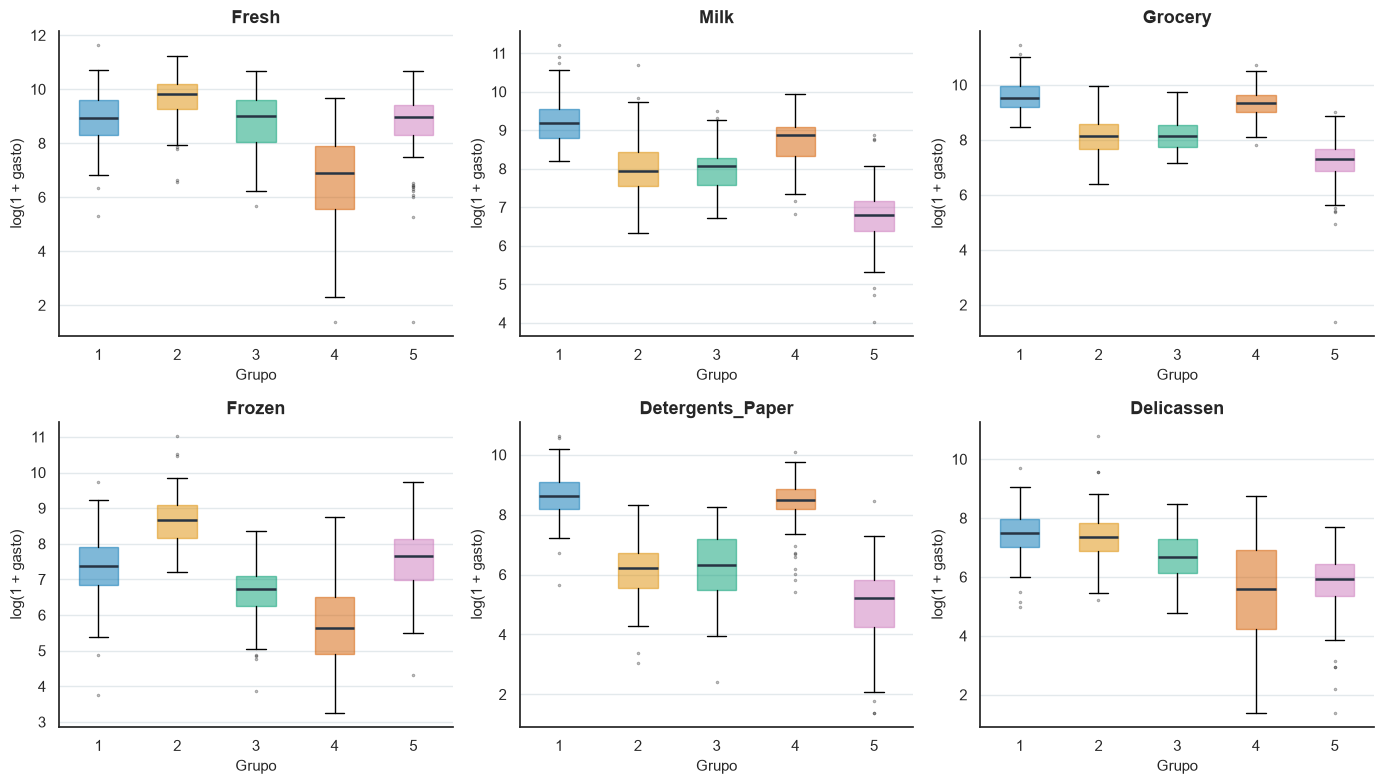

In [79]:
grupos_mayorista = resultados_sistemas[(5, "Hartigan (10)")]
print("Tamaño de cada grupo:")
display(pd.Series(grupos_mayorista + 1, name="Grupo").value_counts().sort_index())
perfiles_mayorista = mayorista.groupby(grupos_mayorista + 1).median()
perfiles_mayorista.index.name = "Grupo"
display(perfiles_mayorista.round(0))
fig, ejes = plt.subplots(2, 3, figsize=(14, 8))
for eje, nombre in zip(ejes.flat, mayorista.columns):
    cajas = [np.log1p(mayorista.loc[grupos_mayorista == g, nombre]) for g in range(5)]
    grafico = eje.boxplot(cajas, patch_artist=True,
                          medianprops={"color": "#273443", "linewidth": 1.8},
                          flierprops={"marker": ".", "markersize": 3, "alpha": 0.35})
    for g, caja in enumerate(grafico["boxes"]):
        _ = caja.set(facecolor=COLORES_GRUPO[g], edgecolor=COLORES_GRUPO[g], alpha=0.5)
    _ = eje.set(title=nombre, xlabel="Grupo", ylabel="log(1 + gasto)")
    _ = estilo_ejes(eje, cuadricula=True)
fig.tight_layout()
plt.show()

### Cierre de la sesión

Redacta una conclusión breve **sin tratar los números de grupo como clases conocidas**:

1. ¿Cómo alteraron escala, distancia y enlace los árboles y los cortes? ¿Qué limitación tiene comparar únicamente la correlación cofenética?
2. Para Iris, ¿coinciden el codo, la silhouette y los votos sobre $k$? ¿Por qué la concordancia con `Species` solo es evaluación externa?
3. ¿Qué cambió en el ejemplo de clientes al aplicar $\log(1+x)$ y al variar algoritmo/inicios? Compara Dunn y silhouette entre $k=5,\ldots,8$, sin olvidar la solución para $k=2$.
4. ¿Por qué PAM, CLARA y el kernel abordan problemas distintos? ¿Qué limitaciones conservan frente a outliers o grupos no convexos?
5. ¿Qué significa un Hopkins próximo a 0 **en la convención de este cuaderno**? ¿Cómo se traduciría al valor de la diapositiva?

**Límite del análisis:** una agrupación depende de variables, escalas y decisiones del algoritmo; no demuestra categorías naturales ni causalidad. Valida estabilidad y utilidad en el contexto antes de emplear segmentos en decisiones reales. Reinicia el kernel y ejecuta todo en orden para comprobar que los ejemplos reproducibles no dependen de cambios hechos con los controles.

### Documentación

- [Clustering jerárquico en SciPy](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html).
- [K-means en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Selección del número de grupos mediante indicadores internos](https://www.jstatsoft.org/article/view/v061i06).